# Прогноз вероятности отмены бронирования

**Задача.** Сеть отелей UrbanStay хочет заранее оценивать вероятность отмены бронирования, чтобы снизить финансовые потери от пустующих номеров и по возможности повысить загрузку (повторно продавать номера, которые с высокой вероятностью освободятся).

**Данные.** Две таблицы PostgreSQL: `hotel_bookings` (бронирования: даты, канал продаж, состав гостей, история клиента, тип номера и т.д.) и `hotel_reviews` (оценки и тексты отзывов гостей по прошлым проживаниям).

**Как оценивается результат.** По трём бизнес-показателям на тестовой выборке: доля отмен бронирования, загрузка отелей и прирост дохода (Incremental Revenue, IR).

## Перевод бизнес-задачи на язык машинного обучения

Задача ставится как **бинарная классификация**: 1 — бронь отменена, 0 — состоявшийся заезд.

План работы:
- собрать данные и присоединить к каждой брони последний прошлый отзыв клиента (`merge_asof` по `customer_id` и датам, только отзывы строго до даты брони);
- создать признаки по бронированиям и по тексту отзывов (TF-IDF);
- сравнить три модели: RandomForest, LightGBM, CatBoost; гиперпараметры подобрать в Optuna, максимизируя относительный Incremental Revenue на кросс-валидации по времени (`TimeSeriesSplit`);
- откалибровать вероятности лучшей модели (`CalibratedClassifierCV`) и найти порог классификации, максимизирующий IR на калибровочной выборке;
- проверить стабильность на тесте, оценить важность признаков и экономический эффект.

## Загрузка необходимых библиотек

Зависимости перечислены в файле `requirements.txt` (`pip install -r requirements.txt`).

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# для SQL
from sqlalchemy import create_engine

#  для проверки корреляции
import phik

# для предобработки текста перед векторизацией
import nltk # импортируем библиотеку nltk для обработки текста
from nltk.corpus import stopwords # импортируем стоп-слова

# для подсчета времени выполнения
import time

# Для работы с пайплайнами, кодированием и моделями
from sklearn.model_selection import cross_val_score,cross_validate, train_test_split, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix,roc_auc_score,accuracy_score, brier_score_loss

# для векторизации текстовых признаков (алгоритм TF–IDF)
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.ensemble import RandomForestClassifier

# XGBoost для задачи классификации
from xgboost import XGBClassifier

# CatBoost для задачи классификации
from catboost import CatBoostClassifier

# LightGBM для задачи классификации
from lightgbm import LGBMClassifier

# Для подбора гиперпараметров
import optuna

# Модули для построения диаграммы калибровки
from sklearn.calibration import CalibratedClassifierCV, calibration_curve, CalibrationDisplay

# для SHAP Values
import shap

import warnings
warnings.filterwarnings('ignore')

import inspect

In [8]:
# Настройка отображения чисел в Pandas (округляем до 4 знаков, убираем e+06)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [9]:
RANDOM_SEED=42

In [10]:
# Константы для расчета бизнес-метрик
AVG_REV = 64500
COST_FP = 7000
LOST_REV = 64500
PER_REBOOKING = 45000

## Этап 1: подготовка данных

### Загрузка данных

- Все данные о работе сети отелей хранятся в базе данных на сервере. Для работы с ними в Python используйте библиотеку SQLAlchemy, чтобы выгрузить данные SQL-запросом.

- Сделайте выводы о проделанной работе.

Параметры подключения (хост, база данных, порт, пользователь, пароль) читаются из файла `.env` (шаблон: `.env.example`) и в ноутбук не записываются.

Названия нужных таблиц: `hotel_bookings` (таблица бронирований) и `hotel_reviews` (таблица отзывов).

In [ ]:
import os
from dotenv import load_dotenv

# Параметры подключения читаются из файла .env (шаблон: .env.example)
load_dotenv()

HOST = os.getenv("DB_HOST")
PORT = os.getenv("DB_PORT", "6432")
DB = os.getenv("DB_NAME")
USER = os.getenv("DB_USER")
PASSWORD = os.getenv("DB_PASSWORD")

# Формируем строку подключения для PostgreSQL
connection_string = f"postgresql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB}"
engine = create_engine(connection_string)

In [12]:
# Выгружаем таблицы в Pandas DataFrame

try:
    # bookings = pd.read_sql_query("SELECT * FROM hotel_bookings;", engine)
    # reviews = pd.read_sql_query("SELECT * FROM hotel_reviews;", engine)
    bookings = pd.read_sql("hotel_bookings", con=engine)
    reviews = pd.read_sql("hotel_reviews", con=engine)
    print(f"Успешно загружено! Бронирований: {bookings.shape[0]}, Отзывов: {reviews.shape[0]}")
except Exception as e:
    print(f"Ошибка при подключении или выгрузке: {e}")

Успешно загружено! Бронирований: 35341, Отзывов: 25177


In [13]:
# Первые строки загруженных таблиц
bookings.head()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,"6,700.0000",21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,"62,300.0000",15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,"46,900.0000",96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,"53,600.0000",150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,"46,900.0000",96,5,2,тип_питания_1,False,тип_1,1


In [14]:
# Установка опции для отображения максимальной ширины столбца
pd.set_option('display.max_colwidth', None)

In [15]:
reviews.head()

,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в номере. Кондиционер не справлялся, тяжело в номере"
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но неработающий лифт."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. здесь всегда ждут как родных
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехника. В номерах холодно. второго одеяла пришлось выпрашивать"
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванной. сервис здесь — это забота на максимум


### Исследовательский анализ данных и предобработка

- Проведите EDA, используя один из следующих инструментов на ваш выбор:

    - библиотеку pandas;
    - SQL-запросы.
    
- EDA должен включать:
    - аналитическое исследование;
    - графическое исследование для количественных данных и для категориальных данных.

- Сделайте выводы о выбросах, пропусках, дубликатах и других аномалиях  в каждой таблице.
- Проведите необходимую предобработку данных.

Проверка пропусков и дубликатов

In [16]:
def explore_data(df, name):
    """
    Функция для первичного анализа датафрейма.
    Выводит размерность, первые строки, информацию о типах данных,
    количество пропусков и дубликатов.
    """

    print(f"Размерность (строки, столбцы): {df.shape}")

    # Первые 5 строк
    display(df.head())

    # Информация о типах данных
    df.info()

    # Анализ пропусков
    missing = df.isna().sum()
    if missing.sum() > 0:
        print(f"\n Найдены пропуски! Количество по столбцам:\n{missing[missing > 0]}")
    else:
        print("\n Пропусков в данных не обнаружено.")

    # Анализ дубликатов
    dups = df.duplicated().sum()
    if dups > 0:
        print(f"\n Найдены полные дубликаты строк: {dups}")
    else:
        print("\n Полных дубликатов строк не обнаружено.")

In [17]:
# Применяем функцию
explore_data(bookings, 'bookings')

Размерность (строки, столбцы): (35341, 17)


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,"6,700.0000",21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,"62,300.0000",15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,"46,900.0000",96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,"53,600.0000",150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,"46,900.0000",96,5,2,тип_питания_1,False,тип_1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   booking_id                 35341 non-null  object        
 1   booking_date               35341 non-null  datetime64[ns]
 2   sales_channel              35341 non-null  object        
 3   adult_count                35341 non-null  int64         
 4   child_count                35341 non-null  int64         
 5   returning_customer         35341 non-null  bool          
 6   previous_cancellations     35341 non-null  int64         
 7   previous_no_shows          35341 non-null  int64         
 8   booking_status             35341 non-null  object        
 9   booking_value              35341 non-null  float64       
 10  days_until_checkin         35341 non-null  int64         
 11  weekday_nights             35341 non-null  int64         
 12  week

In [18]:
# Дублирующиеся строки
# Параметр keep=False чтобы показать все копии дублирующихся строк (и оригинал, и повторы)
# Сортируем по 'booking_id', чтобы одинаковые строки шли друг за другом

duplicates_df = bookings[bookings.duplicated(keep=False)].sort_values(by='booking_id')
duplicates_df.head(10)

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
7,INN00007,2017-08-21,корпоративное_бронирование,2,0,True,1,1,нет_отказа,"67,000.0000",144,8,2,тип_питания_1,False,тип_4,0
33901,INN00007,2017-08-21,корпоративное_бронирование,2,0,True,1,1,нет_отказа,"67,000.0000",144,8,2,тип_питания_1,False,тип_4,0
31377,INN00013,2021-10-22,онлайн_бронирование,3,2,True,0,1,отказ_брони,"53,600.0000",76,6,2,тип_питания_1,False,тип_6,1
13,INN00013,2021-10-22,онлайн_бронирование,3,2,True,0,1,отказ_брони,"53,600.0000",76,6,2,тип_питания_1,False,тип_6,1
33239,INN00022,2020-03-02,корпоративное_бронирование,3,0,True,0,3,отказ_брони,"33,500.0000",77,5,0,тип_питания_1,False,тип_4,1
22,INN00022,2020-03-02,корпоративное_бронирование,3,0,True,0,3,отказ_брони,"33,500.0000",77,5,0,тип_питания_1,False,тип_4,1
27,INN00027,2020-08-21,корпоративное_бронирование,2,1,False,0,0,нет_отказа,"80,400.0000",150,10,2,не выбран,False,тип_4,0
33221,INN00027,2020-08-21,корпоративное_бронирование,2,1,False,0,0,нет_отказа,"80,400.0000",150,10,2,не выбран,False,тип_4,0
48,INN00048,2018-05-20,офлайн_бронирование,2,0,False,0,0,нет_отказа,"67,000.0000",11,8,2,не выбран,False,тип_4,2
32499,INN00048,2018-05-20,офлайн_бронирование,2,0,False,0,0,нет_отказа,"67,000.0000",11,8,2,не выбран,False,тип_4,2


In [19]:
# Удаляем полные дубликаты, оставляя только первое вхождение строки (keep='first')
# Метод .reset_index(drop=True) обновит индексы строк, чтобы не было пропусков
bookings_cleaned = bookings.drop_duplicates(keep='first').reset_index(drop=True)

# Проверяем результат удаления
# Размер исходного датасета bookings
bookings.shape

(35341, 17)

In [20]:
# Размер датасета bookings_cleaned после удаления дубликатов
bookings_cleaned.shape

(30733, 17)

In [21]:
# Проверяем остались ли дубликаты
bookings_cleaned.duplicated().sum()

np.int64(0)

In [22]:
# Перезаписываем исходную переменную очищенными данными для дальнейшей работы
bookings = bookings_cleaned

In [23]:
explore_data(reviews, 'reviews')

Размерность (строки, столбцы): (25177, 5)


,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в номере. Кондиционер не справлялся, тяжело в номере"
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но неработающий лифт."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. здесь всегда ждут как родных
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехника. В номерах холодно. второго одеяла пришлось выпрашивать"
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванной. сервис здесь — это забота на максимум


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  25177 non-null  object        
 1   booking_id   25177 non-null  object        
 2   review_date  25177 non-null  datetime64[ns]
 3   stay_rating  25177 non-null  int64         
 4   review_text  25177 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 983.6+ KB

 Пропусков в данных не обнаружено.

 Полных дубликатов строк не обнаружено.


Результаты показывают:


- **Для таблицы bookings:**

  - Нет пропусков (NaN)
  
  - Дубликаты в таблице - 4608 шт, но они будут устранены при объединении таблиц bookings и reviews

1. Признак с датами имеет тип `object` (строки):
  
  * Для корректной работы с временными рядами и объединения таблиц нам необходимо преобразовать к типу `datetime`:

    - bookings['booking_date ']

2. Имеются признаки с типом `object` (строки) - требует кодирования на этапе препроцессинга данных после объединения таблиц:

      - bookings['booking_id']
      - bookings['sales_channel']
      - bookings['booking_status']
      - bookings['meal_plan']
      - bookings['room_type']





3. В таблице  bookings имеются признаки с типом `boolean` на этапе предобработки данных потребуется преобразование к числовому типу:

     - bookings['returning_customer']
      - bookings['parking_included']


- **Для таблицы reviews:**

  - Нет пропусков (NaN)
  
  - Нет дубликатов

1. Признак с датами имеет тип `object` (строки):
  
  * Для корректной работы с временными рядами и объединения таблиц нам необходимо преобразовать к типу `datetime`:

      - reviews['review_date']
  
2. Имеются признаки с типом `object` (строки) - требует кодирования на этапе препроцессинга данных после объединения таблиц:

      - reviews['customer_id']
      - reviews['booking_id']

3. Иеется `тектовый признак` reviews['review_text'] - требуется на этапе предобработки данных выполнить очистку, векторизацию и токенизацию


**Графический анализ количественных и категориальных данных**

In [24]:
# Настройки для графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

def plot_continuous_feature_distribution(df, column, title=None):
    """Функция для построения гистограммы и boxplot непрерывного числового признака"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Гистограмма
    sns.histplot(df[column].dropna(), bins=50, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Распределение: {column}' if title is None else title)
    axes[0].set_xlabel(column)
    axes[0].set_ylabel('Количество')

    # Boxplot
    sns.boxplot(y=df[column].dropna(), ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot: {column}')
    axes[1].set_ylabel(column)

    plt.tight_layout()
    plt.show()

    # Вывод статистик
    print(f"\n Статистики для '{column}':")
    print(f"  Среднее: {df[column].mean():.2f}")
    print(f"  Медиана: {df[column].median():.2f}")
    print(f"  Мин: {df[column].min():.2f}")
    print(f"  Макс: {df[column].max():.2f}")
    print(f"  Стандартное отклонение: {df[column].std():.2f}")

In [25]:
def plot_discrete_feature_distribution(df, column, title=None):
    """Функция для построения countplot дискретного числового признака"""
    fig = figsize=(14, 5)

    # Countplot
    sns.countplot(data=df.dropna(), x=column, palette='Set2')
    plt.title(f'Распределение: {column}' if title is None else title)
    plt.ylabel('Количество')

    plt.tight_layout()
    plt.show()

    # Вывод статистик
    print(f"\n Статистики для '{column}':")
    print(f"  Среднее: {df[column].mean():.2f}")
    print(f"  Медиана: {df[column].median():.2f}")
    print(f"  Мин: {df[column].min():.2f}")
    print(f"  Макс: {df[column].max():.2f}")
    print(f"  Стандартное отклонение: {df[column].std():.2f}")

In [26]:
def plot_categorical_distribution(df, column, title=None):
    """Функция для построения графика категориального признака"""
    fig = figsize=(14, 5)

    # Countplot (Столбчатая диаграмма)
    # Используем выравнивание подписей ha='right', чтобы при повороте в 45 градусов они не съезжали
    sns.countplot(data=df, x=column, palette='Set2')
    plt.title(f'Распределение: {column}' if title is None else title, fontsize=12)
    plt.ylabel('Количество')
    plt.tick_params(axis='x', rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.5) # добавим легкую сетку по Y

    plt.tight_layout()
    plt.show()

In [27]:
numerical_features = bookings.select_dtypes(include=['int64', 'float64']).columns

numerical_features

Index(['adult_count', 'child_count', 'previous_cancellations',
       'previous_no_shows', 'booking_value', 'days_until_checkin',
       'weekday_nights', 'weekend_nights', 'customer_special_requests'],
      dtype='object')

In [28]:
# Анализ непрерывных и дискретных признаков
analysis_df = pd.DataFrame({
    'Тип данных (Dtype)': bookings[numerical_features].dtypes,
    'Кол-во уникальных значений (nunique)': bookings[numerical_features].nunique(),
    'Пример значений': [bookings[col].unique()[:5] for col in numerical_features] # первые 5 уникальных значений
})

display(analysis_df)

,Тип данных (Dtype),Кол-во уникальных значений (nunique),Пример значений
adult_count,int64,6,"[300, 3, 2, 1, 200]"
child_count,int64,3,"[0, 2, 1]"
previous_cancellations,int64,6,"[0, 1, 2, 3, 4]"
previous_no_shows,int64,6,"[0, 1, 2, 3, 4]"
booking_value,float64,1766,"[6700.0, 62300.0, 46900.0, 53600.0, 44500.0]"
days_until_checkin,int64,79,"[21, 15, 96, 150, 103]"
weekday_nights,int64,14,"[1, 5, 6, 10, 8]"
weekend_nights,int64,4,"[0, 2, 4, 6]"
customer_special_requests,int64,6,"[0, 1, 2, 3, 4]"


bookings['booking_value'] - непрерывный признак

остальные признаки - дискретные

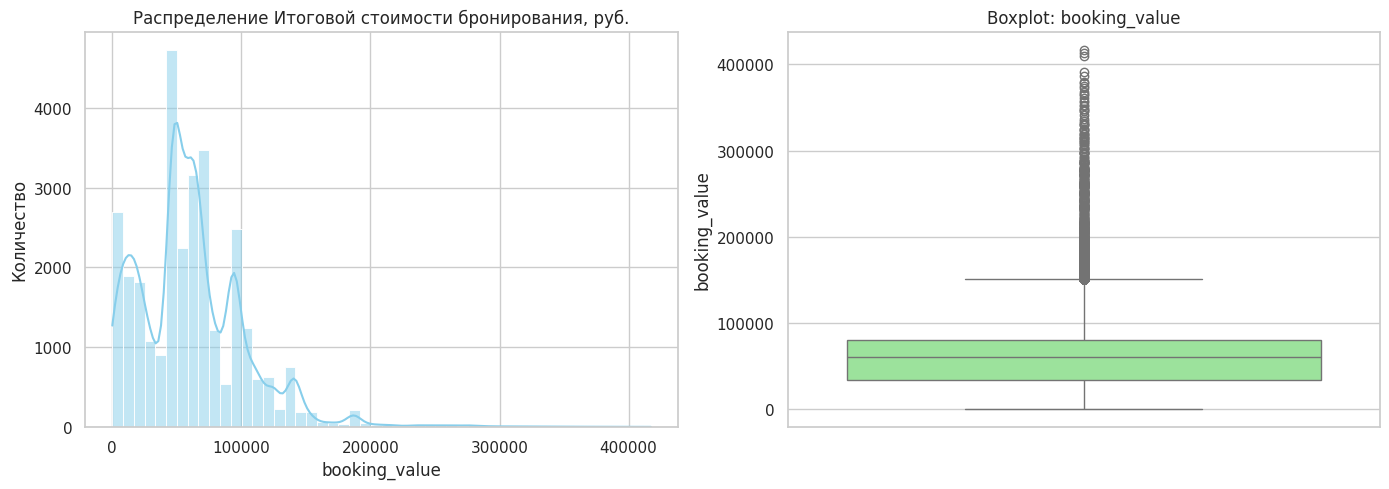


 Статистики для 'booking_value':
  Среднее: 61679.17
  Медиана: 60300.00
  Мин: 0.00
  Макс: 417221.20
  Стандартное отклонение: 42737.29


In [29]:
plot_continuous_feature_distribution(bookings, 'booking_value', title= 'Распределение Итоговой стоимости бронирования, руб.')

- Наблюдается ассиметричность в правую сторону

- Максимальное значение составляет 417 221.20 руб. На графике размаха (Box Plot) видно, что после отметки примерно в 150–160 тыс. рублей начинается плотный поток точек-выбросов. Однако для гостиничного бизнеса это естественные (валидные) выбросы

- Минимальное значение равно 0.00 руб. Наличие нулевой стоимости — это важный сигнал. Это могут быть бронирования по программам лояльности (за бонусы), технические тестовые записи или акции «живи за отзыв».

In [30]:
len(bookings[bookings['booking_value'] == 0])

1229

In [31]:
(len(bookings[bookings['booking_value'] == 0])/len(bookings))*100

3.9989587739563333

In [32]:
# Оставляем только строки с положительной стоимостью
bookings = bookings[bookings['booking_value'] > 0].reset_index(drop=True)

In [33]:
len(bookings[bookings['booking_value'] == 0])

0

~Принято решение сохранить данные строки, так как используемые далее ансамблевые модели (градиентный бустинг) эффективно обрабатывают такие особенности, а их удаление исказило бы последующий расчет экономической эффективности (IR) внедрения модели.~

'booking_value' = 0 удалены

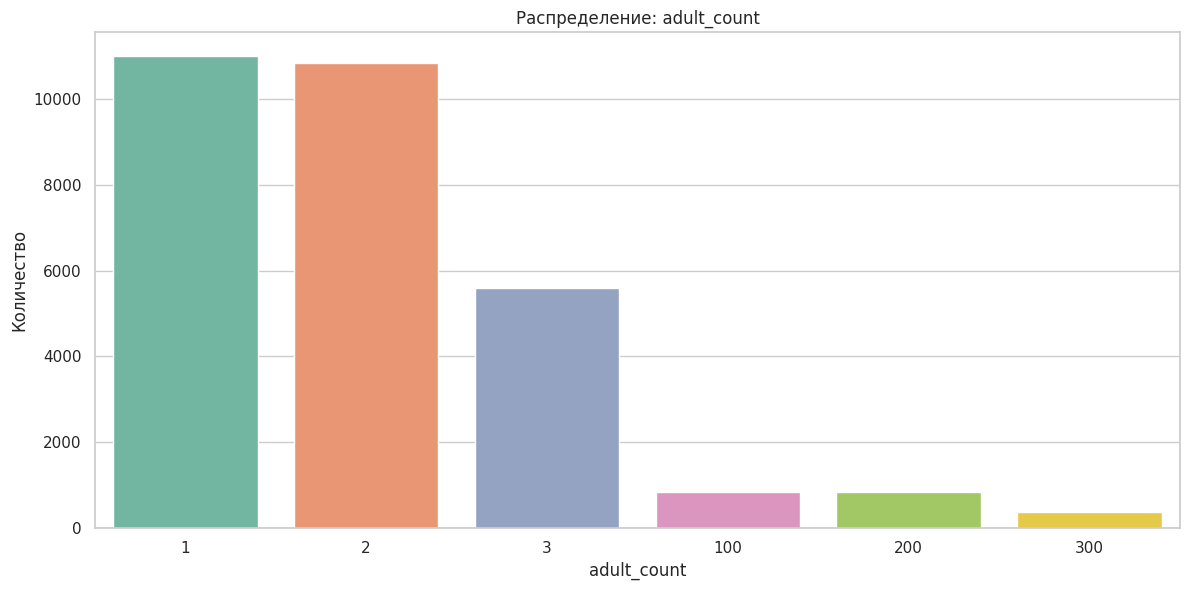


 Статистики для 'adult_count':
  Среднее: 14.00
  Медиана: 2.00
  Мин: 1.00
  Макс: 300.00
  Стандартное отклонение: 48.65


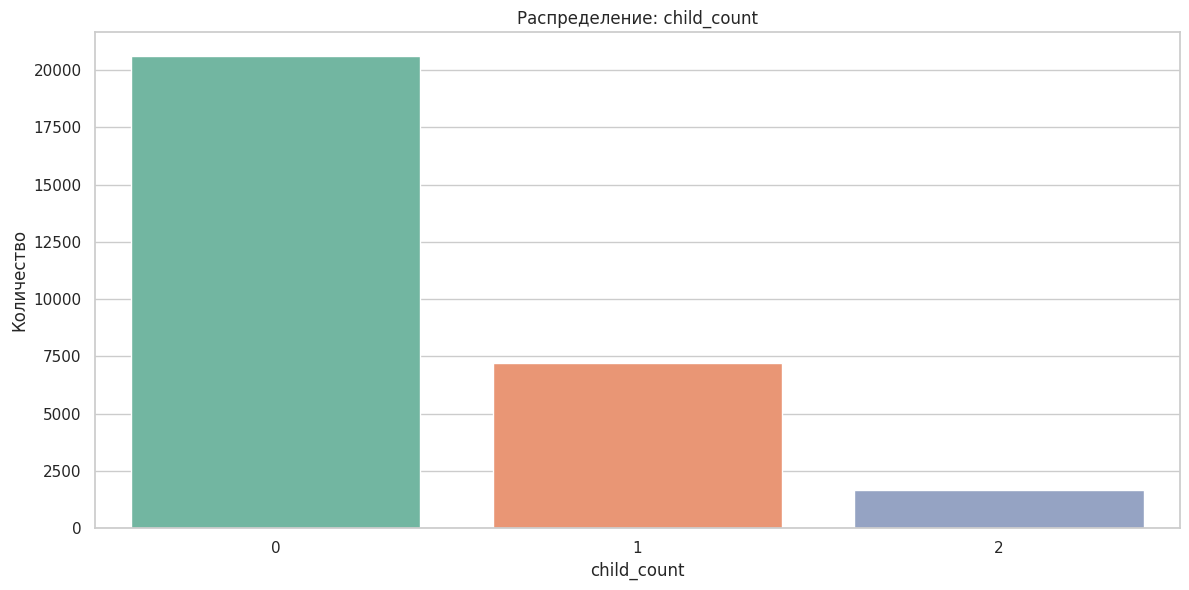


 Статистики для 'child_count':
  Среднее: 0.36
  Медиана: 0.00
  Мин: 0.00
  Макс: 2.00
  Стандартное отклонение: 0.59


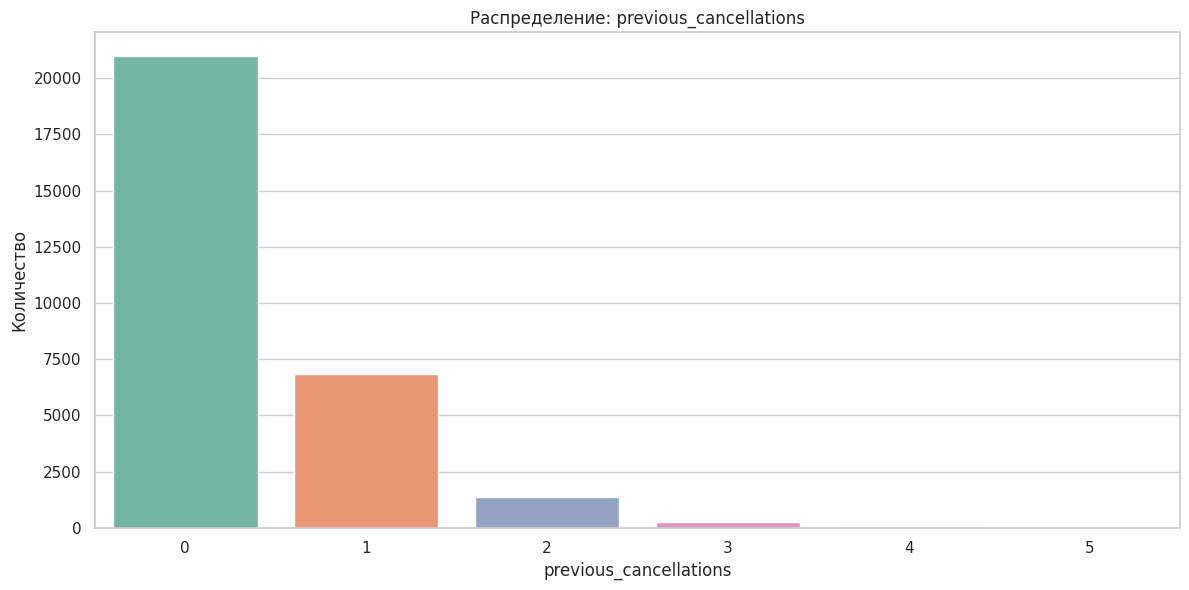


 Статистики для 'previous_cancellations':
  Среднее: 0.36
  Медиана: 0.00
  Мин: 0.00
  Макс: 5.00
  Стандартное отклонение: 0.63


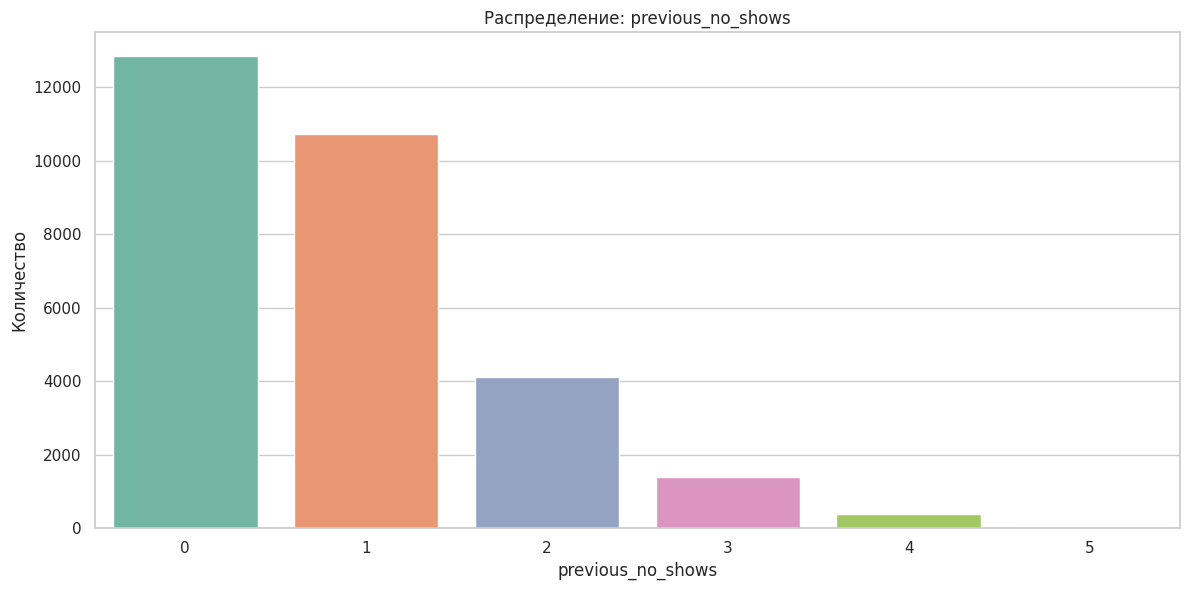


 Статистики для 'previous_no_shows':
  Среднее: 0.84
  Медиана: 1.00
  Мин: 0.00
  Макс: 5.00
  Стандартное отклонение: 0.93


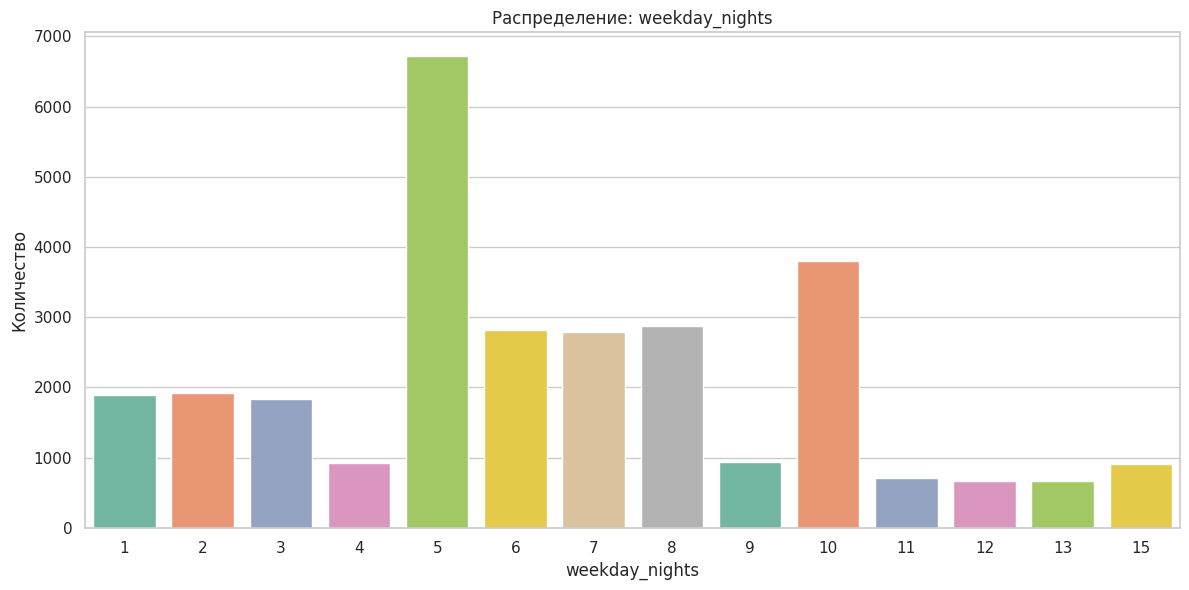


 Статистики для 'weekday_nights':
  Среднее: 6.53
  Медиана: 6.00
  Мин: 1.00
  Макс: 15.00
  Стандартное отклонение: 3.34


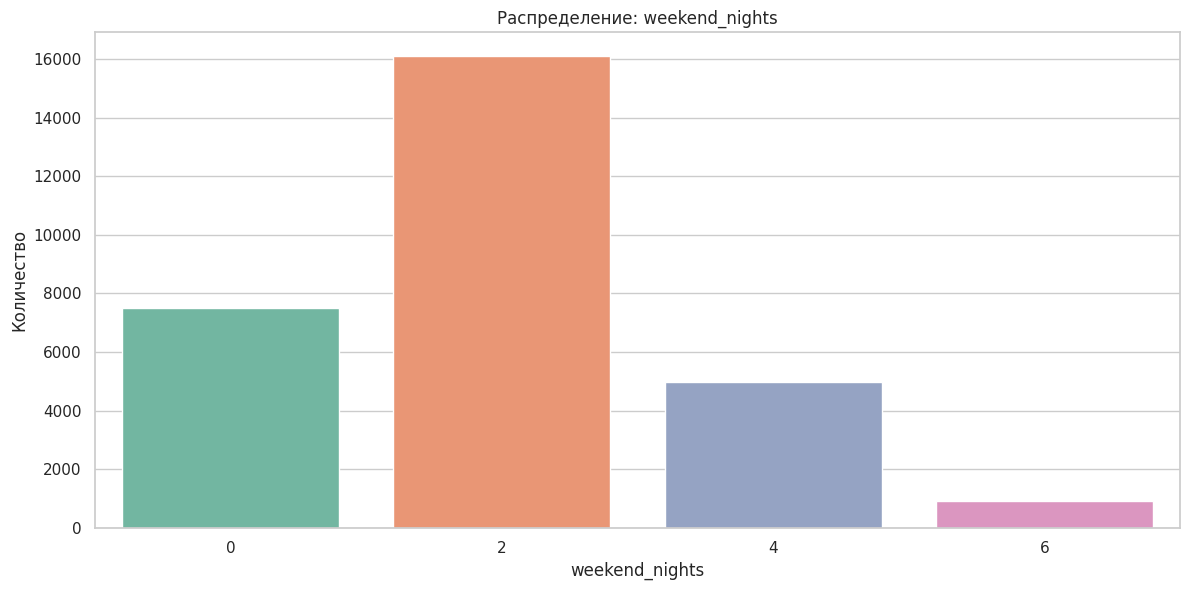


 Статистики для 'weekend_nights':
  Среднее: 1.95
  Медиана: 2.00
  Мин: 0.00
  Макс: 6.00
  Стандартное отклонение: 1.48


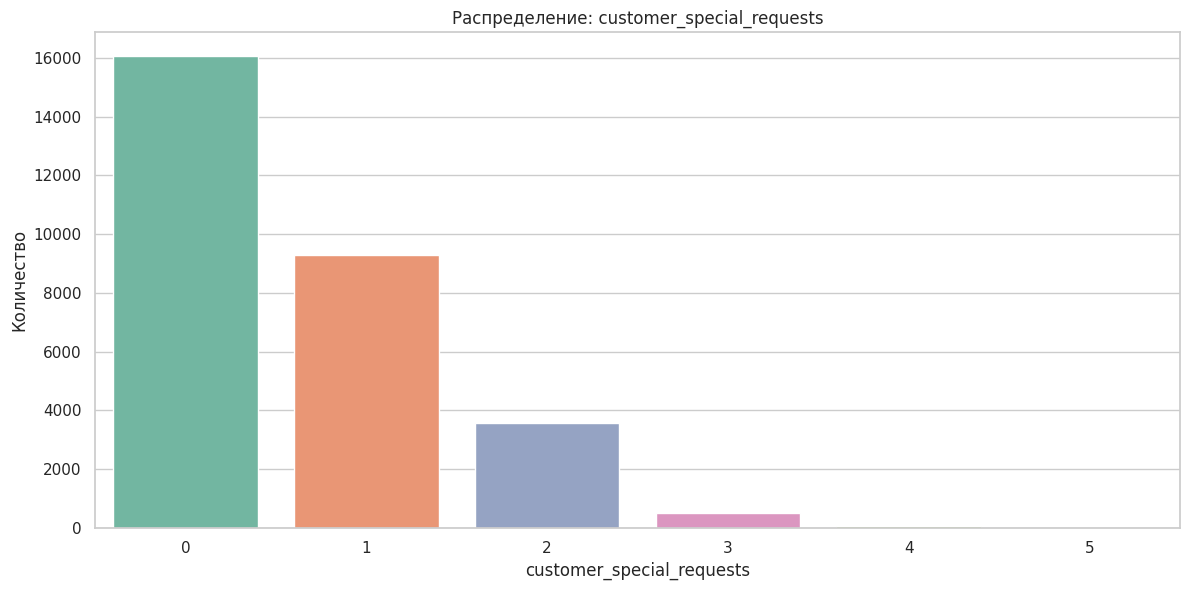


 Статистики для 'customer_special_requests':
  Среднее: 0.62
  Медиана: 0.00
  Мин: 0.00
  Макс: 5.00
  Стандартное отклонение: 0.78


In [34]:
# Убираем 'days_until_checkin' - т.к. для этого дискретного признака с большим количеством значений ужно построить отдельно histplot
discrete_features = bookings.drop(columns=['booking_value','days_until_checkin']).select_dtypes(include=['int64']).columns

for column in discrete_features:
    plot_discrete_feature_distribution(bookings, column, title=None)

In [35]:
# Распределение до исправления
bookings['adult_count'].value_counts().sort_index()

,count
adult_count,
1,11008
2,10835
3,5607
100,848
200,830
300,376


In [36]:
# Исправляем аномалии: если значение >= 100, делим его на 100
bookings['adult_count'] = np.where(
    bookings['adult_count'] >= 100,
    bookings['adult_count'] // 100,
    bookings['adult_count']
)

In [37]:
# Распределение после исправления
bookings['adult_count'].value_counts().sort_index()

,count
adult_count,
1,11856
2,11665
3,5983



 Статистики для 'days_until_checkin':
  Среднее: 100.54
  Медиана: 90.00
  Мин: 2.00
  Макс: 300.00
  Стандартное отклонение: 71.93


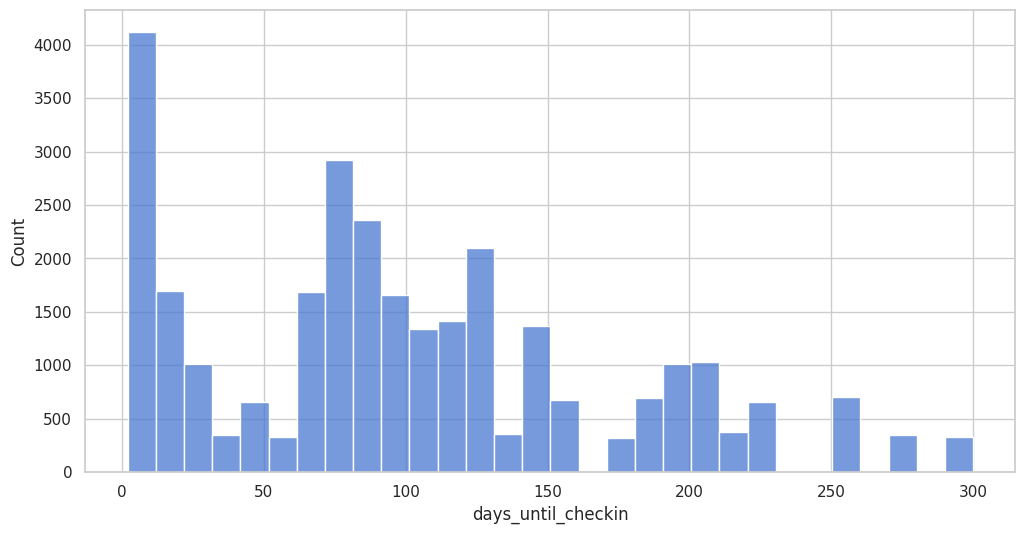

In [38]:
# histplot для 'days_until_checkin'

sns.histplot(data=bookings, x='days_until_checkin', bins=30)

# Вывод статистик
print(f"\n Статистики для 'days_until_checkin':")
print(f"  Среднее: {bookings['days_until_checkin'].mean():.2f}")
print(f"  Медиана: {bookings['days_until_checkin'].median():.2f}")
print(f"  Мин: {bookings['days_until_checkin'].min():.2f}")
print(f"  Макс: {bookings['days_until_checkin'].max():.2f}")
print(f"  Стандартное отклонение: {bookings['days_until_checkin'].std():.2f}")

In [39]:
categorical_features = bookings.select_dtypes(include=['object']).columns
categorical_features

Index(['booking_id', 'sales_channel', 'booking_status', 'meal_plan',
       'room_type'],
      dtype='object')

In [40]:
# Убираем booking_id,booking_date - визуализация не целесообразна, а для booking_status - отдельно визуализация целевой переменной
categorical_features = categorical_features.drop(['booking_id', 'booking_status'])
categorical_features

Index(['sales_channel', 'meal_plan', 'room_type'], dtype='object')

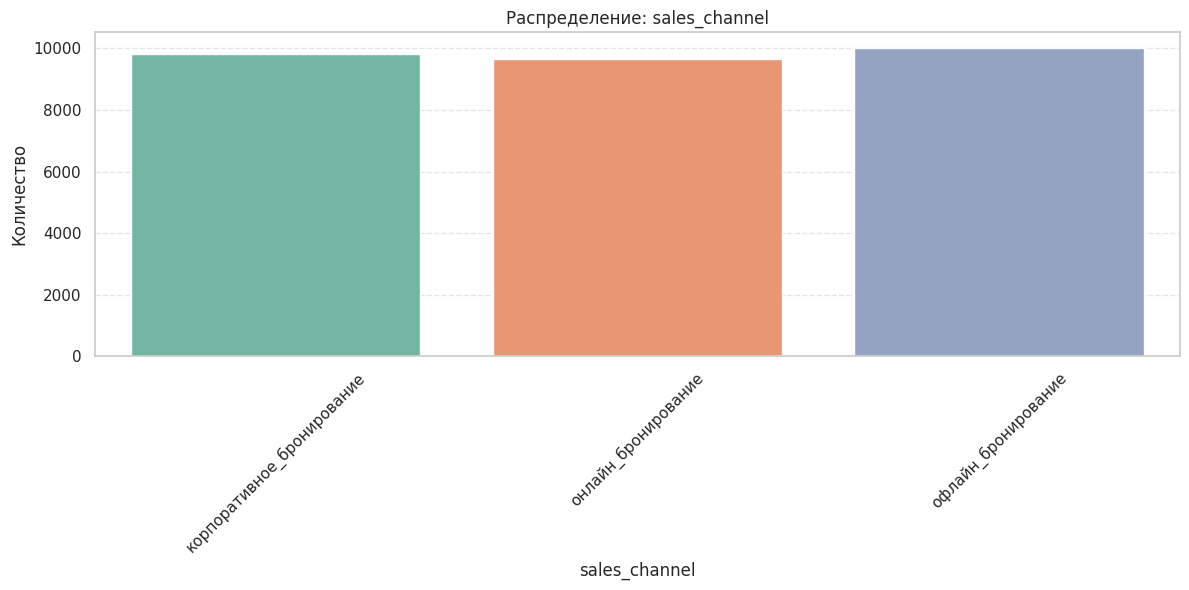

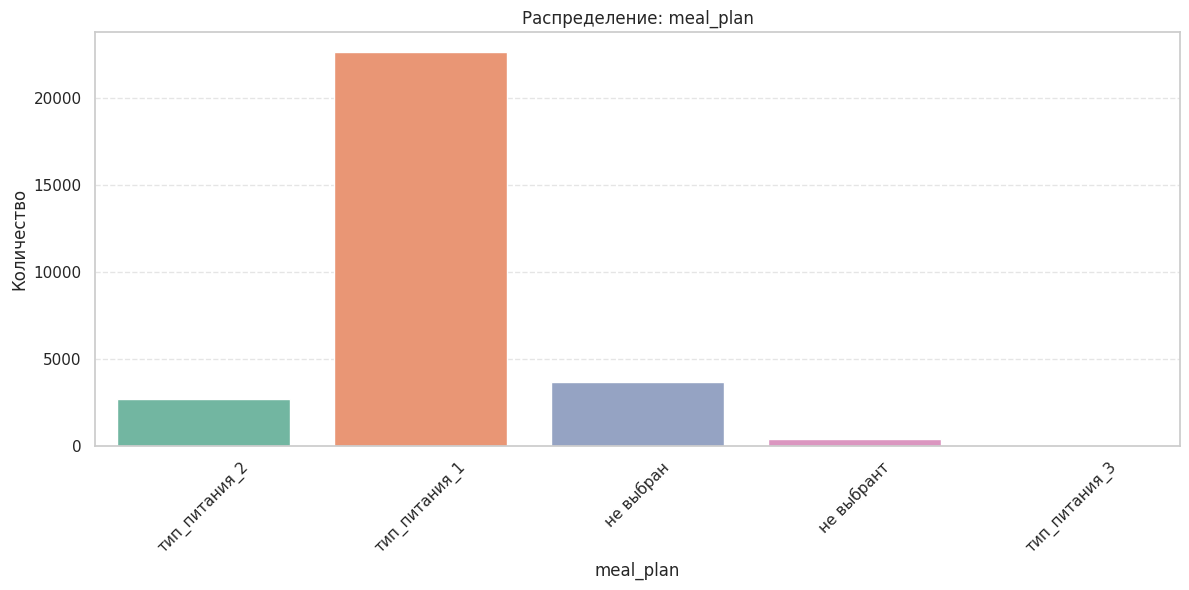

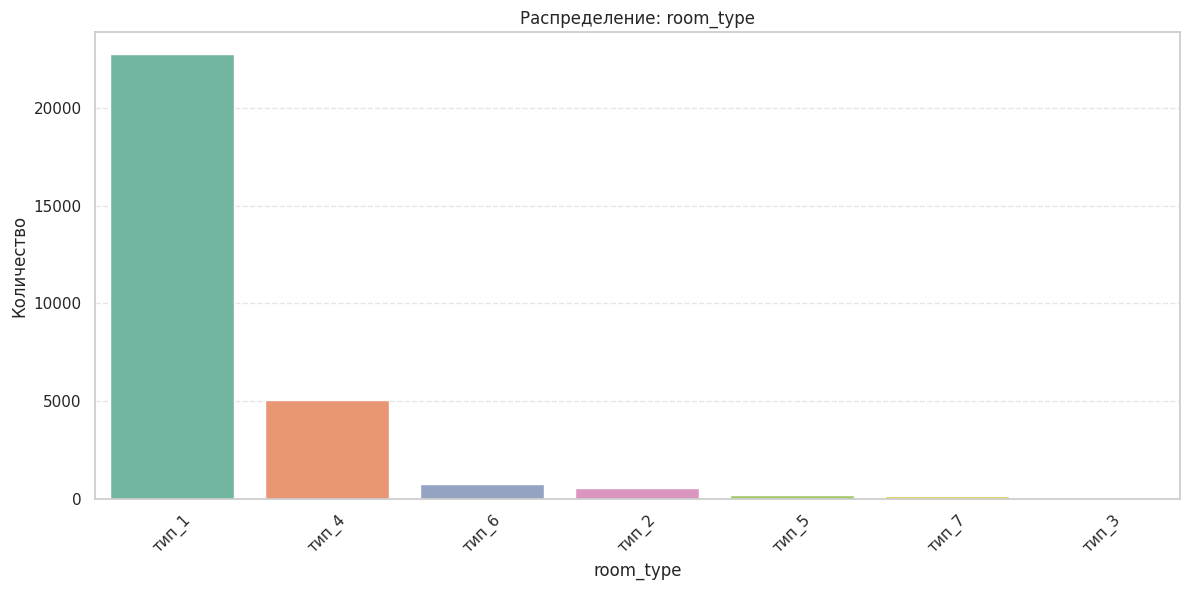

In [41]:
for column in categorical_features:
  plot_categorical_distribution(bookings, column, title=None)

In [42]:
bookings['meal_plan'].unique()

array(['тип_питания_2', 'тип_питания_1', 'не выбран', 'не выбрант',
       'тип_питания_3'], dtype=object)

In [43]:
# Заменим опечатку при написании категории "не выбрант" на "не выбран"
bookings['meal_plan'] = bookings['meal_plan'].replace('не выбрант','не выбран')

In [44]:
bookings['meal_plan'].unique()

array(['тип_питания_2', 'тип_питания_1', 'не выбран', 'тип_питания_3'],
      dtype=object)

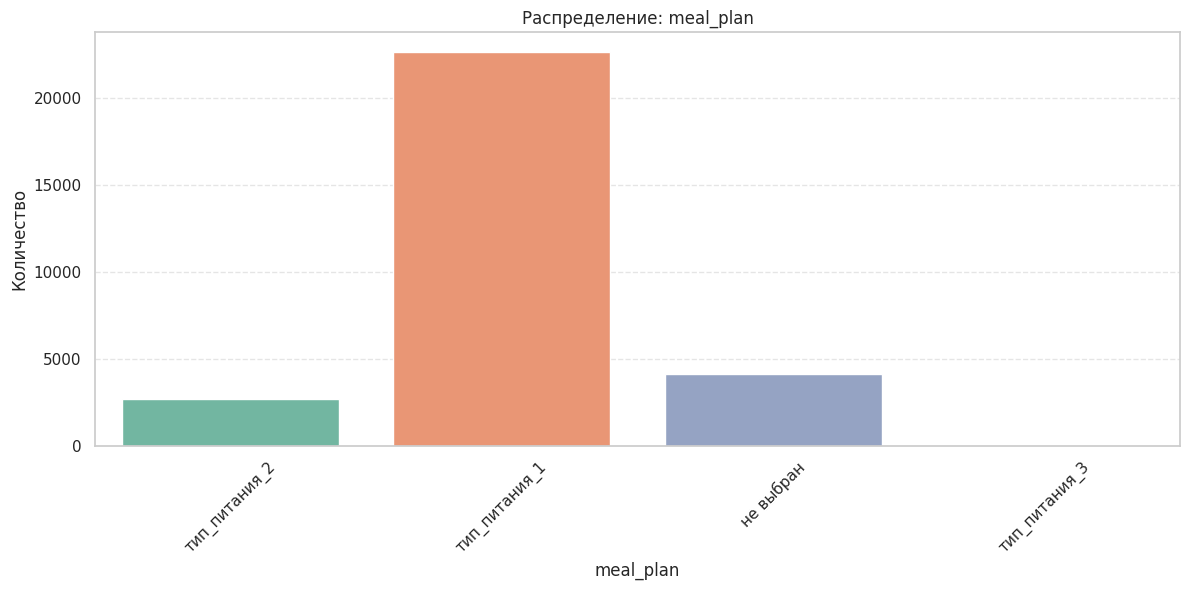

In [45]:
plot_categorical_distribution(bookings, 'meal_plan', title=None)

Text(0, 0.5, 'Количество броней')

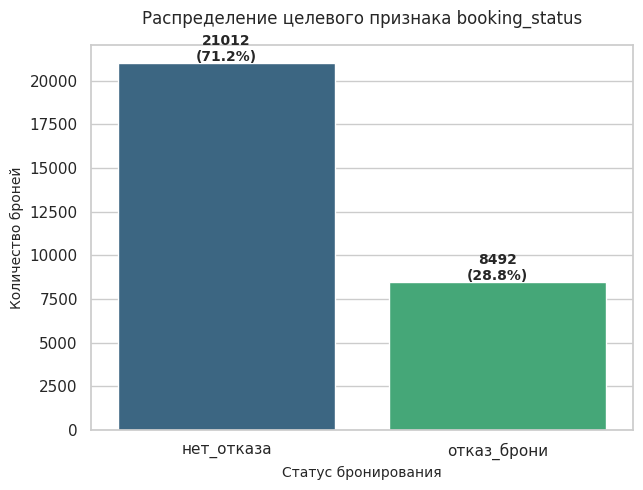

In [46]:
# Распределение целевого признака booking_status (текущий статус бронирования: отказ_брони/нет_отказа

target_col = bookings['booking_status']

plt.figure(figsize=(7, 5))

# Передаем строго текстовое название колонки в параметр x
ax = sns.countplot(data=bookings, x='booking_status', palette='viridis')

# Добавляем подписи с процентами и количеством над каждым столбцом
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / len(bookings):.1f}%'
    ax.annotate(f'{int(height)}\n({percentage})',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center',
                xytext=(0, 10),
                textcoords='offset points',
                fontsize=10, fontweight='bold')

# Настройка названий и заголовков
plt.title('Распределение целевого признака booking_status', fontsize=12, pad=15)
plt.xlabel('Статус бронирования', fontsize=10)
plt.ylabel('Количество броней', fontsize=10)

В данных наблюдается сильный дисбаланс по целевой переменной - необходимо учесть при разбиении данных ~(использовать стратификацию `stratify=y`)~ и при настройке моделей

**Корреляция между признаками целевой переменной**

In [47]:
# Вычисление матрицы корреляции с использованием phik
# Выбираем только смысловые признаки для анализа взаимосвязей
features_for_corr = [
    'booking_status', 'adult_count', 'child_count',
    'previous_cancellations', 'previous_no_shows', 'booking_value',
    'days_until_checkin', 'weekday_nights', 'weekend_nights',
    'customer_special_requests', 'sales_channel', 'meal_plan', 'room_type'
]

# из-за большого количества данных выделим сэмпл данных
df_sample = bookings[features_for_corr].sample(n=10000, random_state=42)

# Указываем ТОЛЬКО непрерывные признаки и исключаем дискретные
interval_cols = ['booking_value']

# Вычисление Phik матрицы, указывая только непрерывные числовые признаки в interval_cols
corr_matrix = df_sample.phik_matrix(interval_cols=interval_cols)

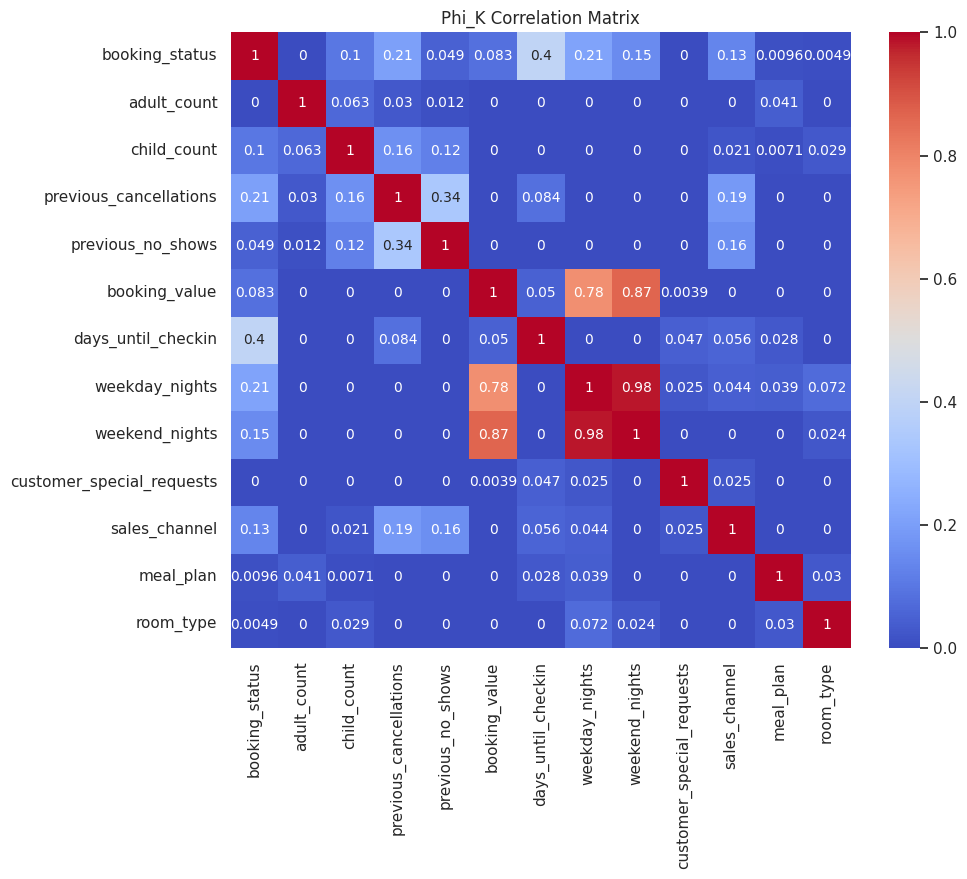

In [48]:
# Визуализация матрицы корреляции
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Phi_K Correlation Matrix')
plt.show()

Наблюдается высокая корреляция между признаками weekend_nights и weekday_nights

In [49]:
# Корреляции целевой переменной booking_status с признаками
phik_click_correlations_all = (corr_matrix['booking_status'].drop('booking_status'))
phik_click_correlations_all.sort_values(ascending=False)

,booking_status
days_until_checkin,0.3997
weekday_nights,0.2134
previous_cancellations,0.2067
weekend_nights,0.1498
sales_channel,0.1331
child_count,0.1011
booking_value,0.0827
previous_no_shows,0.0488
meal_plan,0.0096
room_type,0.0049


**Аналогично для reviews**

In [50]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  25177 non-null  object        
 1   booking_id   25177 non-null  object        
 2   review_date  25177 non-null  datetime64[ns]
 3   stay_rating  25177 non-null  int64         
 4   review_text  25177 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 983.6+ KB


In [51]:
numerical_features = reviews.select_dtypes(include=['int64', 'float64']).columns

numerical_features

Index(['stay_rating'], dtype='object')

In [52]:
# Анализ непрерывных и дискретных признаков
analysis_df = pd.DataFrame({
    'Тип данных (Dtype)': reviews[numerical_features].dtypes,
    'Кол-во уникальных значений (nunique)': reviews[numerical_features].nunique(),
    'Пример значений': [reviews[col].unique()[:5] for col in numerical_features] # первые 5 уникальных значений
})

display(analysis_df)

,Тип данных (Dtype),Кол-во уникальных значений (nunique),Пример значений
stay_rating,int64,4,"[3, 4, 2, 5]"


reviews['stay_rating	'] - дискретный признак

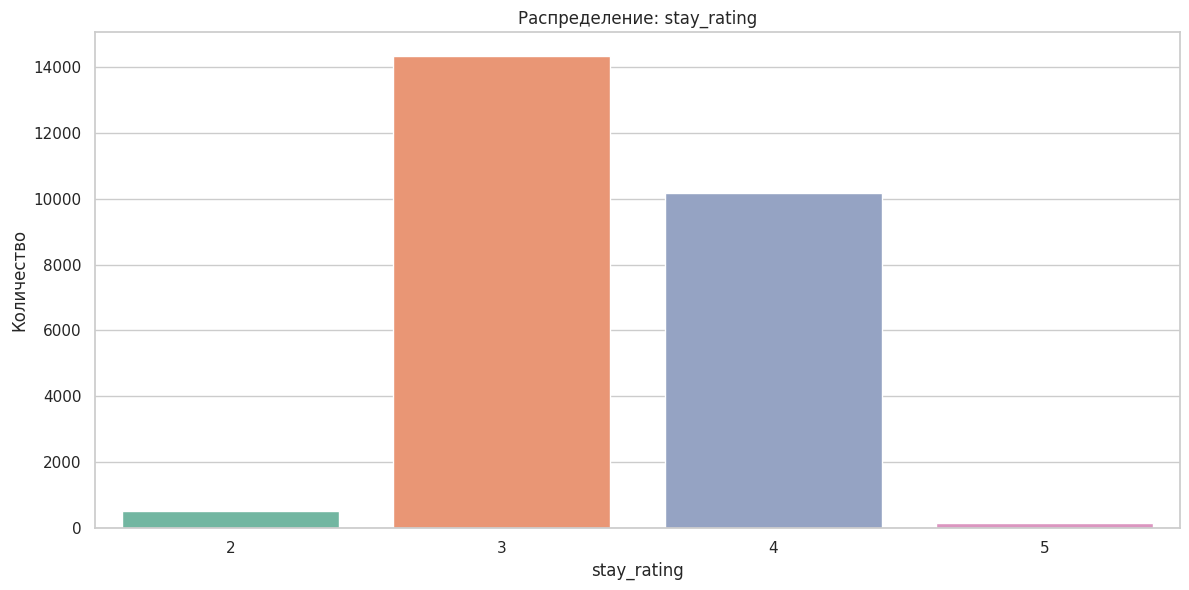


 Статистики для 'stay_rating':
  Среднее: 3.40
  Медиана: 3.00
  Мин: 2.00
  Макс: 5.00
  Стандартное отклонение: 0.54


In [53]:
plot_discrete_feature_distribution(reviews, 'stay_rating', title=None)

In [54]:
categorical_features = reviews.select_dtypes(include=['object']).columns
categorical_features

Index(['customer_id', 'booking_id', 'review_text'], dtype='object')

In [55]:
len(reviews)

25177

In [56]:
reviews['review_text'].nunique()

14153

In [57]:
# Находим количество пропусков NaN
nan_count = reviews['review_text'].isna().sum()
print(f"Количество пропусков (NaN) в отзывах: {nan_count}")

# Смотрим на процент таких строк
nan_percentage = (nan_count / len(reviews)) * 100
print(f"Процент пропусков: {nan_percentage:.2f}%")

Количество пропусков (NaN) в отзывах: 0
Процент пропусков: 0.00%


Для категориальных признаков не целесообразна визуализация

**Корректировка данных и подготовка их к дальнейшим этапам работы:**

In [58]:
bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   booking_id                 29504 non-null  object        
 1   booking_date               29504 non-null  datetime64[ns]
 2   sales_channel              29504 non-null  object        
 3   adult_count                29504 non-null  int64         
 4   child_count                29504 non-null  int64         
 5   returning_customer         29504 non-null  bool          
 6   previous_cancellations     29504 non-null  int64         
 7   previous_no_shows          29504 non-null  int64         
 8   booking_status             29504 non-null  object        
 9   booking_value              29504 non-null  float64       
 10  days_until_checkin         29504 non-null  int64         
 11  weekday_nights             29504 non-null  int64         
 12  week

In [59]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  25177 non-null  object        
 1   booking_id   25177 non-null  object        
 2   review_date  25177 non-null  datetime64[ns]
 3   stay_rating  25177 non-null  int64         
 4   review_text  25177 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 983.6+ KB


In [60]:
# Приведение колонок с датами к формату datetime (критично для Шага 3)

bookings['booking_date'] = pd.to_datetime(bookings['booking_date'])

reviews['review_date'] = pd.to_datetime(reviews['review_date'])

In [61]:
# Преобразование boolean в int
bookings['returning_customer']=bookings['returning_customer'].astype('int8')
bookings['parking_included']=bookings['parking_included'].astype('int8')

In [62]:
bookings['booking_status'].unique()

array(['нет_отказа', 'отказ_брони'], dtype=object)

In [63]:
# Преобразование целевой переменной к типу int 'отказ_брони' = 1, 'нет_отказа' = 0
bookings['booking_status'] = bookings['booking_status'].map({'отказ_брони': 1, 'нет_отказа': 0})

In [64]:
bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   booking_id                 29504 non-null  object        
 1   booking_date               29504 non-null  datetime64[ns]
 2   sales_channel              29504 non-null  object        
 3   adult_count                29504 non-null  int64         
 4   child_count                29504 non-null  int64         
 5   returning_customer         29504 non-null  int8          
 6   previous_cancellations     29504 non-null  int64         
 7   previous_no_shows          29504 non-null  int64         
 8   booking_status             29504 non-null  int64         
 9   booking_value              29504 non-null  float64       
 10  days_until_checkin         29504 non-null  int64         
 11  weekday_nights             29504 non-null  int64         
 12  week

In [65]:
# Проверяем результат
bookings['booking_status'].value_counts()

,count
booking_status,
0,21012
1,8492


**Выполняем  обработку текстав признаке reviews['review_text']**

**Шаги:**

1. Импортировать библиотеку nltk и скачать стоп-слова для русского языка, и создать множество со стоп-словами.

2. Перевести весь текст в нижний регистр с помощью функции lower().

3. Удалить из текстов все специальные символы и лишние пробелы с помощью регулярного выражения.

4. Удалить из текстов все переносы строк с помощью функции strip().

5. Разделить текст на токены с помощью метода split() без аргументов. В этом случае разделителями будут любые последовательности пробельных символов.

In [66]:
# 1 Шаг
nltk.download('stopwords') # скачиваем все существующие стоп-слова

russian_stopwords = set(stopwords.words('russian')) # Объявляем множество из стоп-слов русского языка

# Объявляем функцию для удаления стоп-слов
def remove_stopwords(text_tokens):
    filtered_sentence = [text_token for text_token in text_tokens if text_token not in russian_stopwords] # Оставить здесь только те слова, которых нет во множестве russian_stopwords
    return " ".join(filtered_sentence)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [67]:
# 2 Шаг
reviews['review_text'] = reviews['review_text'].str.lower()

In [68]:
# 3 Шаг
reviews['review_text'] = reviews['review_text'].str.replace(r'[^\w\s]|[\s]+', ' ', regex=True)  # Заменить все спец символы и лишние пробелы на один пробел

In [69]:
# 4 Шаг
reviews['review_text'] = reviews['review_text'].str.strip()

In [70]:
# 5 Шаг
reviews['tokens'] = reviews['review_text'].str.split()

In [71]:
reviews['tokens'] = reviews['tokens'].apply(lambda x: x if isinstance(x, list) else [])

reviews['filtered_sentences'] = reviews['tokens'].apply(remove_stopwords)  # Применяем ранее созданную функцию для удаления стоп-слов

reviews['filtered_sentences'][0]

'неплохо тихо спокойно отсутствие фена номере кондиционер справлялся тяжело номере'

In [72]:
# Проверим результат
reviews.head()

,customer_id,booking_id,review_date,stay_rating,review_text,tokens,filtered_sentences
0,C0001,INN00000,2020-08-21,3,неплохо тихо и спокойно но отсутствие фена в номере кондиционер не справлялся тяжело в номере,"[неплохо, тихо, и, спокойно, но, отсутствие, фена, в, номере, кондиционер, не, справлялся, тяжело, в, номере]",неплохо тихо спокойно отсутствие фена номере кондиционер справлялся тяжело номере
1,C0001,INN00001,2021-10-15,3,неплохо красивое оформление территории но неработающий лифт,"[неплохо, красивое, оформление, территории, но, неработающий, лифт]",неплохо красивое оформление территории неработающий лифт
2,C0001,INN00002,2023-03-08,4,отличный отель удобные парковочные места здесь всегда ждут как родных,"[отличный, отель, удобные, парковочные, места, здесь, всегда, ждут, как, родных]",отличный отель удобные парковочные места ждут родных
3,C0002,INN00003,2017-08-13,3,неплохо тёплый приём но неисправная сантехника в номерах холодно второго одеяла пришлось выпрашивать,"[неплохо, тёплый, приём, но, неисправная, сантехника, в, номерах, холодно, второго, одеяла, пришлось, выпрашивать]",неплохо тёплый приём неисправная сантехника номерах холодно второго одеяла пришлось выпрашивать
4,C0003,INN00004,2019-07-12,4,отличный отель качественная косметика в ванной сервис здесь это забота на максимум,"[отличный, отель, качественная, косметика, в, ванной, сервис, здесь, это, забота, на, максимум]",отличный отель качественная косметика ванной сервис это забота максимум


In [73]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id         25177 non-null  object        
 1   booking_id          25177 non-null  object        
 2   review_date         25177 non-null  datetime64[ns]
 3   stay_rating         25177 non-null  int64         
 4   review_text         25177 non-null  object        
 5   tokens              25177 non-null  object        
 6   filtered_sentences  25177 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 1.3+ MB


### Объединение таблиц

- Соедините таблицу отзывов с таблицей бронирований. Руководствуйтесь правилом: для каждой даты бронирования в столбце `booking_date` нужно взять комментарий и оценку клиента по предыдущей ближайшей дате отзывов, указанной в столбце `review_date`. Это позволит связать обратную связь клиента с конкретным периодом проживания, что критически важно для анализа удовлетворённости гостей.

- Сделайте выводы о том, как прошло объединение и что получилось в результате.

In [74]:
# Сбрасываем индексы, чтобы даты гарантированно были ОБЫЧНЫМИ колонками
bookings = bookings.reset_index(drop=True)
reviews = reviews.reset_index(drop=True)

# Готовим таблицы: они ОБЯЗАТЕЛЬНО должны быть отсортированы по своим датам
bookings = bookings.sort_values(by='booking_date')
reviews = reviews.sort_values(by='review_date')

# В таблице bookings изначально НЕТ колонки customer_id, подтягиваем её
if 'customer_id' not in bookings.columns:
    bookings = bookings.merge(
        reviews[['booking_id', 'customer_id']].drop_duplicates(),
        on='booking_id',
        how='left'
    )
    # После обычного мерджа снова принудительно сортируем по дате
    bookings = bookings.sort_values(by='booking_date')

# Объединяем, явно указав РАЗНЫЕ имена колонок дат через left_on и right_on
#df_merged = pd.merge_asof(
#    bookings,
#    reviews[['customer_id', 'review_date', 'stay_rating', 'review_text']],
#    left_on='booking_date',   # Колонка даты в левой таблице (bookings)
#    right_on='review_date',   # Колонка даты в правой таблице (reviews)
#    by='customer_id',         # Строгое совпадение по клиенту
#    direction='backward'      # Ищем отзывы в прошлом (review_date <= booking_date)
#)

# Восстанавливаем дефолтный индекс и порядок
#df_merged = df_merged.sort_index().reset_index(drop=True)

In [75]:
# Удаляем пропуски в ключевой колонке у отзывов (для корректной работы merge_asof)
reviews = reviews.dropna(subset=['customer_id'])

# Фильтрация броней без customer_id
# Разделяем бронирования на те, где клиент известен, и где нет
bookings_with_id = bookings[bookings['customer_id'].notna()].copy()
bookings_without_id = bookings[bookings['customer_id'].isna()].copy()

# allow_exact_matches=False
# Объединяем только те строки, где есть customer_id
df_merged_with_id = pd.merge_asof(
    bookings_with_id,
    reviews[['customer_id', 'review_date', 'stay_rating', 'review_text']],
    left_on='booking_date',
    right_on='review_date',
    by='customer_id',
    direction='backward',
    allow_exact_matches=False  # Отзыв должен быть строго бронирования (review_date < booking_date)
)

# Для строк без customer_id просто создаем пустые колонки отзывов (они не могут иметь историю)
for col in ['review_date', 'stay_rating', 'review_text']:
    bookings_without_id[col] = None

# Объединяем обе части обратно в один датафрейм
df_merged = pd.concat([df_merged_with_id, bookings_without_id], axis=0)

# Восстанавливаем хронологический порядок по дате бронирования и сбрасываем индекс
df_merged = df_merged.sort_values(by='booking_date').reset_index(drop=True)

In [76]:
# Проверяем, что всё объединилось
df_merged[['booking_date', 'review_date', 'customer_id', 'stay_rating']].tail(10)

,booking_date,review_date,customer_id,stay_rating
29494,2025-05-01,2024-07-20,C7868,4.0000
29495,2025-05-08,NaT,NaN,NaN
29496,2025-05-20,2024-06-15,C7983,3.0000
29497,2025-06-10,2024-05-29,C2572,4.0000
29498,2025-06-30,2024-09-22,C15215,3.0000
29499,2025-07-01,NaT,NaN,NaN
29500,2025-07-01,NaT,NaN,NaN
29501,2025-07-04,2024-07-31,C16085,3.0000
29502,2025-10-02,2024-10-09,C15485,3.0000
29503,2025-10-22,NaT,NaN,NaN


In [77]:
# Размер итогового датасета
df_merged.shape

(29504, 21)

### Создание новых признаков

- Создайте не менее трёх признаков на основе данных о брони.

- Создайте новые признаки на основе текстов отзывов, используя один из методов векторизации. Решение о количестве таких признаков примите самостоятельно.

- Сделать выводы о созданных признаках.

In [78]:
# ПРИЗНАКИ НА ОСНОВЕ ДАННЫХ О БРОНИ

# Сезонность (Косинусная трансформация месяца)
df_merged['booking_month_num_cos'] = np.cos(2 * np.pi * df_merged['booking_date'].dt.month / 12)

# Количество бронирований клиента (считаем по исходному booking_id)
booking_counts = df_merged.groupby('customer_id')['booking_id'].nunique().reset_index(name='booking_num')
df_merged = df_merged.merge(booking_counts, on='customer_id', how='left')
df_merged['booking_num'] = df_merged['booking_num'].fillna(1).astype(int)

# Комплексная оценка лояльности клиента
df_merged['customer_loyalty_score'] = (
    df_merged['returning_customer'] * (1 + df_merged['previous_cancellations']) / df_merged['booking_num']
)

# Дополнительный полезный признак: Общее количество ночей (Убирает сильную мультиколлинеарность)
df_merged['total_nights'] = df_merged['weekday_nights'] + df_merged['weekend_nights']

In [79]:
df_merged.tail()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,...,room_type,customer_special_requests,customer_id,review_date,stay_rating,review_text,booking_month_num_cos,booking_num,customer_loyalty_score,total_nights
29499,INN05316,2025-07-01,онлайн_бронирование,2,0,1,0,4,1,"13,400.0000",...,тип_1,0,NaN,NaT,NaN,None,-0.8660,1,1.0000,2
29500,INN12950,2025-07-01,корпоративное_бронирование,1,0,1,0,4,1,"140,700.0000",...,тип_1,0,NaN,NaT,NaN,None,-0.8660,1,1.0000,21
29501,INN30030,2025-07-04,онлайн_бронирование,1,0,1,0,4,0,"60,300.0000",...,тип_1,0,C16085,2024-07-31,3.0000,неплохо своевременная уборка номеров но холодная еда в ресторане в номерах холодно второго одеяла пришлось выпрашивать,-0.8660,5,0.2000,9
29502,INN28866,2025-10-02,офлайн_бронирование,1,0,1,0,4,0,"46,900.0000",...,тип_1,0,C15485,2024-10-09,3.0000,неплохо отличные условия для детей но недостаточная вентиляция кондиционер не справлялся тяжело в номере,0.5000,5,0.2000,7
29503,INN18736,2025-10-22,офлайн_бронирование,2,0,1,0,4,1,"107,200.0000",...,тип_1,1,NaN,NaT,NaN,None,0.5000,1,1.0000,16


In [80]:
# Проверяем пропуски после объединения таблиц
df_merged.isna().sum()

,0
booking_id,0
booking_date,0
sales_channel,0
adult_count,0
child_count,0
returning_customer,0
previous_cancellations,0
previous_no_shows,0
booking_status,0
booking_value,0


In [81]:
# Заполняем текстовые пропуски заглушкой
df_merged['review_text'] = df_merged['review_text'].fillna('no_review')

In [82]:
# Заполняем пропуски в рейтинге специальным маркером -1 и приводим к целому типу
df_merged['stay_rating'] = df_merged['stay_rating'].fillna(-1).astype(int)

Столбцы, которые не будут добавлены в выборки для обучения моделей:

* booking_id и customer_id (тип object): Это уникальные идентификаторы. Для модели они выглядят как случайный шум. Если оставить customer_id, модель может переобучиться под конкретных людей, запомнив их поведение в прошлом, вместо того чтобы искать общие закономерности.

* booking_date и review_date (тип datetime64): Алгоритмы машинного обучения не умеют напрямую работать с типом данных "дата". Если их оставить, код выдаст ошибку. Всю полезную информацию из дат мы уже извлекли (создали циклическую фичу booking_month_num_cos, которая передает сезонность).

### Анализ итоговой таблицы

- Проанализируйте итоговую таблицу.

- Сделайте выводы о данных для моделирования.

**1. Качество данных и готовность к моделированию**

- Полное отсутствие пропусков: Все 21 колонка имеют 30733 non-null значений.

- Пропуски в текстовых отзывах (review_text), оценках (stay_rating) и категориальных связях были успешно устранены с помощью корректных бизнес-заглушек ('no_review') и маркерных числовых индикаторов (-1).

-  Оптимизация типов данных: Часть признаков (returning_customer, parking_included) была переведена в экономичный тип int8, что снизило нагрузку на оперативную память (memory usage: 4.5+ MB). Это ускорит процесс подбора гиперпараметров в Optuna.

**2. Структура признаков и их подготовка по группам (Feature Types)**

- Перед подачей матрицы в пайплайн обучения признаки необходимо строго разделить на четыре функциональные группы:

* Целевая переменная (Target): booking_status - Бинарный признак (0 — нет отказа, 1 — отказ). Используется только как вектор ответов y.

* Категориальные (Categorical): sales_channel, meal_plan, room_type - Требуют кодирования.

  - Для CatBoost передаются как есть в параметр cat_features.

  - Для LightGBM/XGBoost требуют TargetEncoder или OneHotEncoder.

  - Для RandomForest - можно пробовать как OrdinalEncoder так и OHE.
  
* Числовые непрерывные и дискретные (Numerical): adult_count, child_count, previous_cancellations, previous_no_shows, booking_value, days_until_checkin, weekday_nights, weekend_nights, parking_included, customer_special_requests, stay_rating, booking_month_num_cos, booking_num, customer_loyalty_score, total_nights - предобработка не требуется

  - Для деревьев (бустингов) масштабирование не требуется.

* Текстовые (Text/NLP): review_text - Нельзя передавать как object. Внутри пайплайна к нему должен применяться TfidfVectorizer(max_features=10) строго с обучением на train-выборке во избежание Data Leakage.

**3. Риски и стратегические решения для этапа ML**

- Исключение неинформативных признаков:

  * Из финального набора данных для обучения (X) требуется удалить технические идентификаторы booking_id и customer_id, так как они обладают избыточной кардинальностью и ведут к жесткому переобучению (модель запоминает конкретных людей, а не паттерны поведения).

  * Временной фактор и валидация: Временные признаки booking_date и review_date также должны быть исключены из X, разделение на обучающую и валидационную выборки должно происходить строго хронологически (например, по годам 2013-2016). Случайное разбиение (train_test_split) недопустимо, так как нарушит временную структуру данных о бронированиях.
  
  * Проблема мультиколлинеарности: Введенный признак total_nights успешно компенсирует линейную зависимость между weekday_nights и weekend_nights (phik = 0.98). При использовании алгоритмов, чувствительных к мультиколлинеарности, исходные раздельные ночи weekend_nights и weekday_nights можно исключить из обучения, оставив только суммарный показатель.
  
  * Калибровка вероятностей: Поскольку бизнес-метрики отеля (Approval Rate, Default Rate) напрямую зависят от точности предсказания класса, сырые скоры моделей бустинга необходимо будет пропустить через CalibratedClassifierCV(method='isotonic'), так как бустинги склонны смещать вероятности к экстремумам (0 и 1) из-за специфики минимизации логистической функции потерь.

**Вывод:**

Датасет полностью сбалансирован, очищен от технического шума, обогащен комплексными признаками лояльности и сезонности и готов к интеграции в ColumnTransformer для последующего обучения ансамблей.

**Результаты анализа корреляций признаков (ИАД)**

В ходе исследовательского анализа данных была построена и проанализирована матрица взаимной корреляции признаков (методом phi_K).

Выявлены следующие ключевые закономерности:

  * Связь с целевой переменной (booking_status):
  
    - Наиболее сильную прямую корреляцию с отменой бронирования демонстрирует признак days_until_checkin (Количество дней с момента брони до даты заселения).
  
    Это подтверждает гипотезу: чем раньше совершено бронирование, тем выше вероятность изменения планов у клиента.
  
    - Высокую прямую связь имеют признаки previous_cancellations (Количество отменённых бронирований у клиента в прошлом).
  
    Клиенты, уже нарушавшие правила отеля в прошлом, имеют выраженную склонность к повторным отменам.
  
  * Мультиколлинеарность и избыточность:
  
    - Обнаружена критическая линейная зависимость между признаками weekday_nights (Количество ночей в периоде проживания, которые приходятся на будние дни: с понедельника по пятницу) и weekend_nights (Количество ночей в периоде проживания, которые приходятся на выходные дни — субботу и воскресенье).
  
    Во избежание переобучения моделей и раздувания пространства признаков, в обучение будет передан только агрегированный признак total_nights.
  
    Корреляция между стоимостью бронирования (booking_value) и типом номера (room_type) умеренная, что позволяет оставить оба признака в модели, так как они несут разную семантическую нагрузку.

## Этап 2: моделирование

### Обучение и оптимизация модели

- Выберите и обучите не менее двух моделей из списка:

  - Random Forest;

  - CatBoost;

  - LightGBM;

  - XGBoost;

  - любую другую на ваш выбор.

- Разделите данные на три выборки:
  - Обучающую — для обучения моделей (60% данных);
  - Калибровочную — для проведения калибровки модели (20% данных);
  - Тестовую — для финальной оценки качества выбранной модели (20% данных).

- Проведите кросс-валидацию, используйте три фолда. Размер выборки для валидации — 2000.

- Оптимизируйте гиперпараметры с помощью Optuna. Количество гиперпараметров — не менее трёх. Ключевая метрика для оптимизации — Incremental Revenue.

- Сделайте выводы о том, какая модель показала лучшие результаты.

**Разделение на обучающую, калибровочную и тестовую выборки**

In [83]:
# Сортируем данные по дате
df_merged.sort_values(by=['booking_date'],ascending=True,inplace=True)
df_merged.reset_index(drop=True, inplace=True)

In [84]:
#df_merged.head()
df_merged.tail()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,...,room_type,customer_special_requests,customer_id,review_date,stay_rating,review_text,booking_month_num_cos,booking_num,customer_loyalty_score,total_nights
29499,INN12950,2025-07-01,корпоративное_бронирование,1,0,1,0,4,1,"140,700.0000",...,тип_1,0,NaN,NaT,-1,no_review,-0.8660,1,1.0000,21
29500,INN05316,2025-07-01,онлайн_бронирование,2,0,1,0,4,1,"13,400.0000",...,тип_1,0,NaN,NaT,-1,no_review,-0.8660,1,1.0000,2
29501,INN30030,2025-07-04,онлайн_бронирование,1,0,1,0,4,0,"60,300.0000",...,тип_1,0,C16085,2024-07-31,3,неплохо своевременная уборка номеров но холодная еда в ресторане в номерах холодно второго одеяла пришлось выпрашивать,-0.8660,5,0.2000,9
29502,INN28866,2025-10-02,офлайн_бронирование,1,0,1,0,4,0,"46,900.0000",...,тип_1,0,C15485,2024-10-09,3,неплохо отличные условия для детей но недостаточная вентиляция кондиционер не справлялся тяжело в номере,0.5000,5,0.2000,7
29503,INN18736,2025-10-22,офлайн_бронирование,2,0,1,0,4,1,"107,200.0000",...,тип_1,1,NaN,NaT,-1,no_review,0.5000,1,1.0000,16


In [85]:
# Выделяем целевую переменную

X = df_merged.drop(columns=['booking_id', 'customer_id', 'booking_date', 'review_date', 'weekday_nights', 'weekend_nights', 'booking_status']).copy()
y = df_merged['booking_status'].copy()

In [86]:
# Разбиение на выборки
# Разбиение по времени: без перемешивания (shuffle=False) и без stratify
X_train_calibrate, X_test, y_train_calibrate, y_test = train_test_split(X, y, test_size=0.2, shuffle=False, random_state=42)

X_train, X_calibrate, y_train, y_calibrate = train_test_split(X_train_calibrate, y_train_calibrate, test_size=0.2,shuffle=False, random_state=42)

In [87]:
X_train.shape

(18882, 18)

In [88]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18882 entries, 0 to 18881
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sales_channel              18882 non-null  object 
 1   adult_count                18882 non-null  int64  
 2   child_count                18882 non-null  int64  
 3   returning_customer         18882 non-null  int8   
 4   previous_cancellations     18882 non-null  int64  
 5   previous_no_shows          18882 non-null  int64  
 6   booking_value              18882 non-null  float64
 7   days_until_checkin         18882 non-null  int64  
 8   meal_plan                  18882 non-null  object 
 9   parking_included           18882 non-null  int8   
 10  room_type                  18882 non-null  object 
 11  customer_special_requests  18882 non-null  int64  
 12  stay_rating                18882 non-null  int64  
 13  review_text                18882 non-null  object 


In [89]:
y_train.shape

(18882,)

In [90]:
X_calibrate.shape

(4721, 18)

In [91]:
X_test.shape

(5901, 18)

**Предобработка данных и формирование Pipeline**

In [92]:
feature_cols = X_train.columns.to_list()

feature_cols

['sales_channel',
 'adult_count',
 'child_count',
 'returning_customer',
 'previous_cancellations',
 'previous_no_shows',
 'booking_value',
 'days_until_checkin',
 'meal_plan',
 'parking_included',
 'room_type',
 'customer_special_requests',
 'stay_rating',
 'review_text',
 'booking_month_num_cos',
 'booking_num',
 'customer_loyalty_score',
 'total_nights']

In [93]:
# Категориальные признаки для кодирования
cat_columns = X.select_dtypes(include=['object']).columns
categorical_features = cat_columns.drop(['review_text'])
categorical_features

Index(['sales_channel', 'meal_plan', 'room_type'], dtype='object')

In [94]:
# Подготовка признаков перед циклом

# Текстовый признак для векторизации
text_features = 'review_text'

categorical_features_list = categorical_features.to_list()
categorical_features_list

['sales_channel', 'meal_plan', 'room_type']

In [95]:
# Числовые признаки (для деревьев масштабирование не требуется, поэтому не преобразовываем)
numerical_features = [col for col in feature_cols if (col not in categorical_features) & (col not in text_features)]
numerical_features

['adult_count',
 'child_count',
 'returning_customer',
 'previous_cancellations',
 'previous_no_shows',
 'booking_value',
 'days_until_checkin',
 'parking_included',
 'customer_special_requests',
 'stay_rating',
 'booking_month_num_cos',
 'booking_num',
 'customer_loyalty_score',
 'total_nights']

In [97]:
# 1. Препроцессор для Random Forest (OneHotEncoder)
rf_preprocessor = ColumnTransformer(
    transformers=[('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)],
    remainder='passthrough'
)

# Для LightGBM и CatBoost отдельный препроцессор не нужен: категориальные признаки передаются в формате category
#2. Препроцессор для LightGBM (OrdinalEncoder)
#lgbm_preprocessor = ColumnTransformer(
#    transformers=[('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)],
#    remainder='passthrough'
#)

# Создаем словарь пайплайнов
#pipelines = {
#    'catboost_pipeline': Pipeline([
#        # CatBoost сам кодирует категории по именам колонок, препроцессор ему не нужен
#        ('clf', CatBoostClassifier(cat_features=categorical_features.to_list(), random_seed=RANDOM_SEED, verbose=0))
#    ]),
#
#    'lgbm_pipeline': Pipeline([
#        ('prep', lgbm_preprocessor),
#        ('clf', LGBMClassifier(random_state=RANDOM_SEED, n_jobs=-1, verbose=0))
#    ]),
#
#    'rf_balanced_pipeline': Pipeline([
#        ('prep', rf_preprocessor),
#        ('clf', RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1))
#    ])
#}

**Кросс-валидация с соблюдением хронологии (временных интервалов)**

In [98]:
'''all_results = []

# Настройка TimeSeriesSplit (3 фолда по 2000 строк на валидацию)
tscv = TimeSeriesSplit(n_splits=3, test_size=2000)

# Цикл кросс-валидации
for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X_train)):

    # Нарезаем фолды по строкам
    X_train_fold = X_train.iloc[train_idx].copy()
    X_val_fold = X_train.iloc[val_idx].copy()

    y_train_fold = y_train.iloc[train_idx].copy()
    y_val_fold = y_train.iloc[val_idx].copy()

    print(f"\n--- Расчет Фолда {fold_idx + 1} ---")
    print(f"Размер обучения: {len(X_train_fold)} | Размер валидации: {len(X_val_fold)}")

    # Внутренний цикл по моделям
    for model_name, pipeline in pipelines.items():

        # Обучение модели на текущем фолде
        pipeline.fit(X_train_fold, y_train_fold)

        # Предсказания
        y_pred = pipeline.predict(X_val_fold)
        y_pred_proba = pipeline.predict_proba(X_val_fold)

        # Расчет метрик
        tn, fp, fn, tp = confusion_matrix(y_val_fold, y_pred).ravel()
        roc_auc = roc_auc_score(y_val_fold, y_pred_proba[:, 1])
        accuracy = accuracy_score(y_val_fold, y_pred)

        all_results.append({
            'Model': model_name,
            'Fold': f'Fold {fold_idx + 1}',
            'ROC-AUC': round(roc_auc, 4),
            'Accuracy': round(accuracy, 4)
        })

        print(f"Модель: {model_name:20} | ROC-AUC: {roc_auc:.3f} | Accuracy: {accuracy:.3f}")

# Сбор результатов в итоговый DataFrame
df_results = pd.DataFrame(all_results)'''

'all_results = []\n\n# Настройка TimeSeriesSplit (3 фолда по 2000 строк на валидацию)\ntscv = TimeSeriesSplit(n_splits=3, test_size=2000)\n\n# Цикл кросс-валидации\nfor fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X_train)):\n\n    # Нарезаем фолды по строкам\n    X_train_fold = X_train.iloc[train_idx].copy()\n    X_val_fold = X_train.iloc[val_idx].copy()\n\n    y_train_fold = y_train.iloc[train_idx].copy()\n    y_val_fold = y_train.iloc[val_idx].copy()\n\n    print(f"\n--- Расчет Фолда {fold_idx + 1} ---")\n    print(f"Размер обучения: {len(X_train_fold)} | Размер валидации: {len(X_val_fold)}")\n\n    # Внутренний цикл по моделям\n    for model_name, pipeline in pipelines.items():\n\n        # Обучение модели на текущем фолде\n        pipeline.fit(X_train_fold, y_train_fold)\n\n        # Предсказания\n        y_pred = pipeline.predict(X_val_fold)\n        y_pred_proba = pipeline.predict_proba(X_val_fold)\n\n        # Расчет метрик\n        tn, fp, fn, tp = confusion_matrix(y

In [99]:
# Функция для расчета IR
def calculate_fold_ir(y_true, y_pred):
    """Функция расчета IR для фолда"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    ir_after = (tp * PER_REBOOKING) + (tn * AVG_REV) - (fp * COST_FP) - (fn * LOST_REV)
    return ir_after

In [100]:
# Оптимизация для LightGBM: переводим категории в тип 'category' для встроенного кодирования
X_train_lgbm = X_train.copy()
for col in categorical_features_list:
    X_train_lgbm[col] = X_train_lgbm[col].astype('category')

In [101]:
X_train_lgbm.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18882 entries, 0 to 18881
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   sales_channel              18882 non-null  category
 1   adult_count                18882 non-null  int64   
 2   child_count                18882 non-null  int64   
 3   returning_customer         18882 non-null  int8    
 4   previous_cancellations     18882 non-null  int64   
 5   previous_no_shows          18882 non-null  int64   
 6   booking_value              18882 non-null  float64 
 7   days_until_checkin         18882 non-null  int64   
 8   meal_plan                  18882 non-null  category
 9   parking_included           18882 non-null  int8    
 10  room_type                  18882 non-null  category
 11  customer_special_requests  18882 non-null  int64   
 12  stay_rating                18882 non-null  int64   
 13  review_text                18882 non

In [102]:
# Для Random Forest готовим OrdinalEncoder (вместо раздувающего матрицу OHE)
rf_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

In [103]:
# Кросс-валидация с временными интервалами
all_results = []
tscv = TimeSeriesSplit(n_splits=3, test_size=2000)

for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X_train)):
    print(f"\n--- Расчет Фолда {fold_idx + 1} ---")

    # Нарезаем фолды
    y_train_fold = y_train.iloc[train_idx].copy().reset_index(drop=True)
    y_val_fold = y_train.iloc[val_idx].copy().reset_index(drop=True)

    # Базовые фолды для CatBoost и RF
    X_train_fold = X_train.iloc[train_idx].copy().reset_index(drop=True)
    X_train_fold.columns = X_train_fold.columns.astype(str)

    X_val_fold = X_train.iloc[val_idx].copy().reset_index(drop=True)
    X_val_fold.columns = X_val_fold.columns.astype(str)

    # Специальные фолды для LightGBM (с типом данных 'category')
    X_train_fold_lgb = X_train_lgbm.iloc[train_idx].copy().reset_index(drop=True)
    X_train_fold_lgb.columns = X_train_fold_lgb.columns.astype(str)

    X_val_fold_lgb = X_train_lgbm.iloc[val_idx].copy().reset_index(drop=True)
    X_val_fold_lgb.columns = X_val_fold_lgb.columns.astype(str)

    # Обучаем TF-IDF строго на обучающей подвыборке фолда
    tfidf = TfidfVectorizer(max_features=10)

    tfidf_train_matrix = tfidf.fit_transform(X_train_fold[text_features].fillna(''))
    tfidf_val_matrix = tfidf.transform(X_val_fold[text_features].fillna(''))

    tfidf_cols = [f'text_{i}' for i in range(10)]

    df_tfidf_train = pd.DataFrame(tfidf_train_matrix.toarray(), columns=tfidf_cols)
    df_tfidf_val = pd.DataFrame(tfidf_val_matrix.toarray(), columns=tfidf_cols)

    # Присоединяем текстовые фичи и удаляем сырую колонку текста
    X_train_fold = pd.concat([X_train_fold.drop(columns=[text_features]), df_tfidf_train], axis=1)
    X_val_fold = pd.concat([X_val_fold.drop(columns=[text_features]), df_tfidf_val], axis=1)

    X_train_fold_lgb = pd.concat([X_train_fold_lgb.drop(columns=[text_features]), df_tfidf_train], axis=1)
    X_val_fold_lgb = pd.concat([X_val_fold_lgb.drop(columns=[text_features]), df_tfidf_val], axis=1)

    # гарантируем, что типы колонок после конкатенации остались строками
    X_train_fold.columns = X_train_fold.columns.astype(str)
    X_val_fold.columns = X_val_fold.columns.astype(str)
    X_train_fold_lgb.columns = X_train_fold_lgb.columns.astype(str)
    X_val_fold_lgb.columns = X_val_fold_lgb.columns.astype(str)

    # Для Random Forest преобразование категориальных данных выполняем с помощью rf_encoder с Ordinal Encoder
    X_train_fold_rf = X_train_fold.copy()
    X_val_fold_rf = X_val_fold.copy()

    X_train_fold_rf[categorical_features_list] = rf_encoder.fit_transform(X_train_fold_rf[categorical_features_list].astype(str))
    X_val_fold_rf[categorical_features_list] = rf_encoder.transform(X_val_fold_rf[categorical_features_list].astype(str))

    # Из-за ошибки обработки названий колонок с разными типами:
    # Принудительно приводим имена колонок к единому строковому формату
    X_train_fold_rf.columns = [str(col) for col in X_train_fold_rf.columns]
    X_val_fold_rf.columns = [str(col) for col in X_val_fold_rf.columns]


    # Инициализация моделей на текущий фолд
    models = {
        'CatBoost': CatBoostClassifier(cat_features=categorical_features_list, random_seed=RANDOM_SEED, verbose=0),
        'LightGBM': LGBMClassifier(random_state=RANDOM_SEED, n_jobs=-1, verbose=-1), # Встроенная кодировка категорий активирована автоматически
        'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1)
    }

    # Обучение и оценка по ключевой метрике IR
    for model_name, model in models.items():
        # Выбираем правильные датасеты в зависимости от модели
        if model_name == 'LightGBM':
            X_tr, X_va = X_train_fold_lgb, X_val_fold_lgb
        elif model_name == 'Random Forest':
            X_tr, X_va = X_train_fold_rf, X_val_fold_rf
        else:
            X_tr, X_va = X_train_fold, X_val_fold

        # Обучаем модель
        model.fit(X_tr, y_train_fold)

        # Делаем предсказания
        y_pred = model.predict(X_va)
        y_pred_proba = model.predict_proba(X_va)[:, 1]

        # Считаем метрики (Бизнес-метрика IR)
        fold_ir = calculate_fold_ir(y_val_fold, y_pred)
        roc_auc = roc_auc_score(y_val_fold, y_pred_proba)
        accuracy = accuracy_score(y_val_fold, y_pred)

        all_results.append({
            'Model': model_name,
            'Fold': f'Fold {fold_idx + 1}',
            'Incremental Revenue (IR)': fold_ir,
            'ROC-AUC': round(roc_auc, 4),
            'Accuracy': round(accuracy, 4)
        })

        print(f"Модель: {model_name:15} | IR: {fold_ir:12,.0f} руб. | ROC-AUC: {roc_auc:.3f}")


--- Расчет Фолда 1 ---
Модель: CatBoost        | IR:   88,304,500 руб. | ROC-AUC: 0.924
Модель: LightGBM        | IR:   86,646,500 руб. | ROC-AUC: 0.920
Модель: Random Forest   | IR:   87,877,500 руб. | ROC-AUC: 0.921

--- Расчет Фолда 2 ---
Модель: CatBoost        | IR:   89,433,500 руб. | ROC-AUC: 0.936
Модель: LightGBM        | IR:   90,106,000 руб. | ROC-AUC: 0.937
Модель: Random Forest   | IR:   89,938,500 руб. | ROC-AUC: 0.934

--- Расчет Фолда 3 ---
Модель: CatBoost        | IR:   89,587,000 руб. | ROC-AUC: 0.930
Модель: LightGBM        | IR:   90,063,000 руб. | ROC-AUC: 0.932
Модель: Random Forest   | IR:   88,483,000 руб. | ROC-AUC: 0.928


In [104]:
# Сбор и усреднение результатов по фолдам
df_results = pd.DataFrame(all_results)
df_final_summary = df_results.groupby(['Model'])[['Incremental Revenue (IR)', 'ROC-AUC', 'Accuracy']].mean()

In [105]:
# Форматируем вывод IR для красоты
df_final_summary['Incremental Revenue (IR)'] = df_final_summary['Incremental Revenue (IR)'].map('{:,.2f} руб.'.format)
df_final_summary

,Incremental Revenue (IR),ROC-AUC,Accuracy
Model,,,
CatBoost,"89,108,333.33 руб.",0.9299,0.8488
LightGBM,"88,938,500.00 руб.",0.9294,0.8480
Random Forest,"88,766,333.33 руб.",0.9274,0.8108


Модель catboost_pipeline показала наивысший средний результат как по бизнес-метрике `IR = 89,108,333.33`, так и по ROC-AUC=0.9299, Accuracy = 0.8488

In [106]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18882 entries, 0 to 18881
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sales_channel              18882 non-null  object 
 1   adult_count                18882 non-null  int64  
 2   child_count                18882 non-null  int64  
 3   returning_customer         18882 non-null  int8   
 4   previous_cancellations     18882 non-null  int64  
 5   previous_no_shows          18882 non-null  int64  
 6   booking_value              18882 non-null  float64
 7   days_until_checkin         18882 non-null  int64  
 8   meal_plan                  18882 non-null  object 
 9   parking_included           18882 non-null  int8   
 10  room_type                  18882 non-null  object 
 11  customer_special_requests  18882 non-null  int64  
 12  stay_rating                18882 non-null  int64  
 13  review_text                18882 non-null  object 


In [107]:
X_calibrate.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4721 entries, 18882 to 23602
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sales_channel              4721 non-null   object 
 1   adult_count                4721 non-null   int64  
 2   child_count                4721 non-null   int64  
 3   returning_customer         4721 non-null   int8   
 4   previous_cancellations     4721 non-null   int64  
 5   previous_no_shows          4721 non-null   int64  
 6   booking_value              4721 non-null   float64
 7   days_until_checkin         4721 non-null   int64  
 8   meal_plan                  4721 non-null   object 
 9   parking_included           4721 non-null   int8   
 10  room_type                  4721 non-null   object 
 11  customer_special_requests  4721 non-null   int64  
 12  stay_rating                4721 non-null   int64  
 13  review_text                4721 non-null   objec

**Функция расчета бизнес-метрик**

Более интересна формула:
IRпосле​=(TP×PerRebooking)+(TN×AvgRev)−(FP×CostFP)−(FN×LostRev)

Здесь мы уже отталкиваемся от предсказаний модели:
TP — верно предсказанные отмены бронирования.
PerRebooking — стоимость повторной сдачи номеров, бронь на которые отменилась. Вовремя замеченная отмена даёт возможность сдать номер кому-то другому, это обеспечивает дополнительную прибыль.
TN — количество случаев, когда модель не предсказала отмены и бронь действительно состоялась, гость вовремя заехал и оплатил номер.
FP — ложные отмены бронирования — модель предсказала отмену, но гости приехали.
CostFP — стоимость одного ложного предсказания отмены бронирования, компенсации, ущерб от потери лояльности, административные издержки.
FN — пропущенные отмены — модель не предсказала отмену, но она произошла.

Разберем по порядку:
TP×PerRebooking - мы считаем прибыль от во время замеченных отмен, которые смогли перепродать дважды. Далее TN×AvgRev - это чистая прибыль, то есть правильно предсказанные негативы (не-отмены) умноженные на среднюю прибыль. Ну и далее по сути по схожему принципу отнимаем прибыль упущенную из-за ложно предсказанных позитивов и отрицательного класса.

In [108]:
def calculate_business_metrics(y_true, y_pred):
    """
    Рассчитывает абсолютный IR, относительный IR, динамику отмен и динамику загрузки
    в строгом соответствии с формулами бизнес-метрик
    y_true: реальный статус (1 - отмена, 0 - успешный заезд)
    y_pred: предсказание модели (1 - отмена, 0 - успешный заезд)
    """
    # labels=[0, 1] защищает от ValueError, если в выборке встретился только один класс
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    total_bookings = len(y_true)

    # Показатели до внедрения модели
    total_success_before = np.sum(y_true == 0)      # сколько реально приехало
    total_cancellations_before = np.sum(y_true == 1) # сколько реально отменилось

    # Чистый доход до внедрения модели
    revenue_before = (total_success_before * AVG_REV) - (total_cancellations_before * LOST_REV)

    # Доход после внедрения модели
    revenue_after = (tp * PER_REBOOKING) + (tn * AVG_REV) - (fp * COST_FP) - (fn * LOST_REV)

    # Рассчитываем прирост(Incremental Revenue) IR=IRпосле−IRдо​

    ir_absolute = revenue_after - revenue_before

    # Расчет Относительного прироста: Относительный IR=(IRпосле−IRдо)/IRдо×100%

    if revenue_before != 0:
        relative_ir = (ir_absolute / revenue_before) * 100
    else:
        relative_ir = 0.0

    # Динамика доли отмен бронирования
    share_cancellations_before = total_cancellations_before / total_bookings
    share_cancellations_after = fn / total_bookings

    if share_cancellations_before > 0:
        # (Доля отмен до - Доля отмен после)/Доля отмен до*100
        dynamics_cancellations = ((share_cancellations_before - share_cancellations_after) / share_cancellations_before) * 100
    else:
        dynamics_cancellations = 0.0

    # Динамика загрузки отеля:
    # Загрузка до: доля успешно заехавших: Загрузка отеля до = Число занятых номеров до модели/Число доступных номеров до модели

    loading_before = total_success_before / total_bookings

    # Загрузка после: Живут только те, кто подтвердился (TN) : Загрузка отеля после = Число занятых номеров после модели/Число доступных номеров после модели
    # Ошибочные отмены (FP) привели к потере гостей, они не заселились.
    loading_after = tn / total_bookings

    if loading_before > 0:
        # Считаем падение/изменение загрузки по формуле: Динамика загрузки отеля = (Загрузка отеля до - Загрузка отеля после)/Загрузка отеля до*100
        dynamics_loading = ((loading_before - loading_after) / loading_before) * 100
    else:
        dynamics_loading = 0.0

    return {
        'Revenue_Before': revenue_before,
        'Revenue_After': revenue_after,
        'IR_Absolute': ir_absolute,              # Честный чистый прирост
        'IR_Relative_Pct': relative_ir,          # Относительный прирост в %
        'Cancellation_Dynamics_Pct': dynamics_cancellations,
        'Loading_Dynamics_Pct': dynamics_loading, # Корректная динамика без учета FP
        'Loading_Before_Pct': loading_before * 100,
        'Loading_After_Pct': loading_after * 100
    }

**Оптимизация гиперпараметров моделей с помощью Optuna**

In [109]:
def objective_catboost(trial):
    # Настройка пространства поиска (Search Space)
    params = {
        'iterations': trial.suggest_int('iterations', 50, 250),
        'depth': trial.suggest_int('depth', 4, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 4.0),
        'random_seed': RANDOM_SEED,
        'verbose': 0
    }

    tscv = TimeSeriesSplit(n_splits=3, test_size=2000)
    fold_ir_scores = []

    for train_idx, val_idx in tscv.split(X_train):
        # Нарезаем целевую переменную
        y_train_fold = y_train.iloc[train_idx].copy().reset_index(drop=True)
        y_val_fold = y_train.iloc[val_idx].copy().reset_index(drop=True)

        # Нарезаем базовые признаки с явным копированием
        X_train_fold = X_train.iloc[train_idx].copy().reset_index(drop=True)
        X_val_fold = X_train.iloc[val_idx].copy().reset_index(drop=True)

        # приводим к строкам базовые имена колонок
        X_train_fold.columns = [str(col) for col in X_train_fold.columns]
        X_val_fold.columns = [str(col) for col in X_val_fold.columns]

        # Обучаем TF-IDF строго внутри фолда (избегание утечек данных)
        tfidf = TfidfVectorizer(max_features=10)

        tfidf_train_matrix = tfidf.fit_transform(X_train_fold[text_features].fillna(''))
        tfidf_val_matrix = tfidf.transform(X_val_fold[text_features].fillna(''))

        tfidf_cols = [f'text_{i}' for i in range(10)]

        df_tfidf_train = pd.DataFrame(tfidf_train_matrix.toarray(), columns=tfidf_cols)
        df_tfidf_val = pd.DataFrame(tfidf_val_matrix.toarray(), columns=tfidf_cols)

        # Присоединяем текстовые фичи и удаляем сырую колонку текста
        X_train_fold = pd.concat([X_train_fold.drop(columns=[text_features]), df_tfidf_train], axis=1)
        X_val_fold = pd.concat([X_val_fold.drop(columns=[text_features]), df_tfidf_val], axis=1)

        # тип колонок строка
        X_train_fold.columns = [str(col) for col in X_train_fold.columns]
        X_val_fold.columns = [str(col) for col in X_val_fold.columns]

        # Обучаем модель напрямую (категории кодирует сам CatBoost)
        model = CatBoostClassifier(cat_features=categorical_features_list, **params)
        model.fit(X_train_fold, y_train_fold)

        # Предсказание
        y_pred = model.predict(X_val_fold)

        # Считаем бизнес-метрику на фолде
        metrics = calculate_business_metrics(y_val_fold, y_pred)

        # Оптимизируем по абсолютному приросту прибыли (в рублях) или по относительному (%)
        fold_ir_scores.append(metrics['IR_Relative_Pct'])

    # Возвращаем среднее значение Incremental Revenue по фолдам
    return np.mean(fold_ir_scores)

# Запуск исследования Optuna
# Направление 'maximize', так как мы максимизируем чистую прибыль отеля
study_cb = optuna.create_study(direction='maximize')
study_cb.optimize(objective_catboost, n_trials=15)

print("Лучшие параметры CatBoost:", study_cb.best_params)
print(f"Максимальный средний IR: {study_cb.best_value:,.2f} % (относительный IR)")

[I 2026-06-27 07:45:57,303] A new study created in memory with name: no-name-ad1d346c-a40e-4c8f-8e20-c69541cd35d7
[I 2026-06-27 07:46:02,303] Trial 0 finished with value: 66.06666373563128 and parameters: {'iterations': 84, 'depth': 6, 'learning_rate': 0.05974835274728546, 'l2_leaf_reg': 0.003299881790496238, 'scale_pos_weight': 3.58881698952534}. Best is trial 0 with value: 66.06666373563128.
[I 2026-06-27 07:46:08,594] Trial 1 finished with value: 67.29083363734433 and parameters: {'iterations': 125, 'depth': 4, 'learning_rate': 0.04838080279018984, 'l2_leaf_reg': 0.512987418617074, 'scale_pos_weight': 3.254470063378145}. Best is trial 1 with value: 67.29083363734433.
[I 2026-06-27 07:46:41,727] Trial 2 finished with value: 73.09171191561416 and parameters: {'iterations': 242, 'depth': 7, 'learning_rate': 0.02385287124180025, 'l2_leaf_reg': 0.026845284739039913, 'scale_pos_weight': 1.6161740970462322}. Best is trial 2 with value: 73.09171191561416.
[I 2026-06-27 07:47:00,069] Trial 3

Лучшие параметры CatBoost: {'iterations': 209, 'depth': 7, 'learning_rate': 0.026779330131631994, 'l2_leaf_reg': 0.013320249012272075, 'scale_pos_weight': 2.0055425203895085}
Максимальный средний IR: 73.36 % (относительный IR)


In [110]:
def objective_lgbm(trial):
    # Настройка пространства поиска (Search Space)
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 250),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 4.0),
        'random_state': RANDOM_SEED,
        'n_jobs': -1,
        'verbose': -1  # Убираем лишние предупреждения LightGBM в выводе Optuna
    }

    tscv = TimeSeriesSplit(n_splits=3, test_size=2000)
    fold_ir_scores = []


    for train_idx, val_idx in tscv.split(X_train_lgbm):
        # Нарезаем целевую переменную
        y_train_fold = y_train.iloc[train_idx].copy().reset_index(drop=True)
        y_val_fold = y_train.iloc[val_idx].copy().reset_index(drop=True)

        # Нарезаем признаки из X_train_lgbm (где категории приведены к типу 'category')
        X_train_fold_lgb = X_train_lgbm.iloc[train_idx].copy().reset_index(drop=True)
        X_val_fold_lgb = X_train_lgbm.iloc[val_idx].copy().reset_index(drop=True)

        # Предварительно приводим базовые имена колонок к строкам
        X_train_fold_lgb.columns = [str(col) for col in X_train_fold_lgb.columns]
        X_val_fold_lgb.columns = [str(col) for col in X_val_fold_lgb.columns]

        # Обучаем TF-IDF строго внутри фолда (избегание утечек данных)
        tfidf = TfidfVectorizer(max_features=10)

        tfidf_train_matrix = tfidf.fit_transform(X_train_fold_lgb[text_features].fillna(''))
        tfidf_val_matrix = tfidf.transform(X_val_fold_lgb[text_features].fillna(''))

        tfidf_cols = [f'text_{i}' for i in range(10)]

        df_tfidf_train = pd.DataFrame(tfidf_train_matrix.toarray(), columns=tfidf_cols)
        df_tfidf_val = pd.DataFrame(tfidf_val_matrix.toarray(), columns=tfidf_cols)

        # Присоединяем текстовые фичи и удаляем сырую колонку текста
        X_train_fold_lgb = pd.concat([X_train_fold_lgb.drop(columns=[text_features]), df_tfidf_train], axis=1)
        X_val_fold_lgb = pd.concat([X_val_fold_lgb.drop(columns=[text_features]), df_tfidf_val], axis=1)

        #  тип колонок строка
        X_train_fold_lgb.columns = [str(col) for col in X_train_fold_lgb.columns]
        X_val_fold_lgb.columns = [str(col) for col in X_val_fold_lgb.columns]

        # Инициализируем и обучаем модель напрямую (встроенное кодирование LightGBM)
        model = LGBMClassifier(**params)
        model.fit(X_train_fold_lgb, y_train_fold)

        # Предсказание
        y_pred = model.predict(X_val_fold_lgb)

        # Считаем бизнес-метрику на фолде
        metrics = calculate_business_metrics(y_val_fold, y_pred)

        # Добавляем абсолютный IR (чистый прирост в рублях)
        fold_ir_scores.append(metrics['IR_Relative_Pct'])

    # Возвращаем среднее значение Incremental Revenue по фолдам
    return np.mean(fold_ir_scores)

# Запуск исследования Optuna для LightGBM
study_lgb = optuna.create_study(direction='maximize')
study_lgb.optimize(objective_lgbm, n_trials=15)

print("Лучшие параметры LightGBM:", study_lgb.best_params)
print(f"Максимальный средний IR: {study_lgb.best_value:,.2f} % (относительный IR)")

[I 2026-06-27 07:53:34,127] A new study created in memory with name: no-name-47475b72-2556-441b-b851-1450bd1ab847
[I 2026-06-27 07:53:35,564] Trial 0 finished with value: 69.62548933557247 and parameters: {'n_estimators': 230, 'max_depth': 4, 'learning_rate': 0.08891740111109483, 'min_child_samples': 41, 'scale_pos_weight': 2.914146970205917}. Best is trial 0 with value: 69.62548933557247.
[I 2026-06-27 07:53:36,544] Trial 1 finished with value: 71.26819917624297 and parameters: {'n_estimators': 97, 'max_depth': 6, 'learning_rate': 0.011721572627363654, 'min_child_samples': 80, 'scale_pos_weight': 2.093703414726326}. Best is trial 1 with value: 71.26819917624297.
[I 2026-06-27 07:53:37,803] Trial 2 finished with value: 72.8037785085297 and parameters: {'n_estimators': 193, 'max_depth': 4, 'learning_rate': 0.08962322528503198, 'min_child_samples': 92, 'scale_pos_weight': 2.172599207686772}. Best is trial 2 with value: 72.8037785085297.
[I 2026-06-27 07:53:38,822] Trial 3 finished with v

Лучшие параметры LightGBM: {'n_estimators': 193, 'max_depth': 4, 'learning_rate': 0.08962322528503198, 'min_child_samples': 92, 'scale_pos_weight': 2.172599207686772}
Максимальный средний IR: 72.80 % (относительный IR)


In [111]:
def objective_rf(trial):
    # Настройка пространства поиска (Search Space)
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 30, 150),
        'max_depth': trial.suggest_int('max_depth', 5, 15),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'class_weight': trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample', None]),
        'random_state': RANDOM_SEED,
        'n_jobs': -1
    }

    tscv = TimeSeriesSplit(n_splits=3, test_size=2000)
    fold_ir_scores = []

    text_features = 'review_text'
    categorical_features_list = categorical_features.to_list()

    # Инициализируем OrdinalEncoder
    rf_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

    for train_idx, val_idx in tscv.split(X_train):
        # Нарезаем целевую переменную
        y_train_fold = y_train.iloc[train_idx].copy().reset_index(drop=True)
        y_val_fold = y_train.iloc[val_idx].copy().reset_index(drop=True)

        # Нарезаем базовые признаки с явным копированием
        X_train_fold = X_train.iloc[train_idx].copy().reset_index(drop=True)
        X_val_fold = X_train.iloc[val_idx].copy().reset_index(drop=True)

        # Предварительно приводим базовые имена колонок к строкам
        X_train_fold.columns = [str(col) for col in X_train_fold.columns]
        X_val_fold.columns = [str(col) for col in X_val_fold.columns]

        # Обучаем TF-IDF строго внутри фолда (избегание утечек данных)
        tfidf = TfidfVectorizer(max_features=10)

        tfidf_train_matrix = tfidf.fit_transform(X_train_fold[text_features].fillna(''))
        tfidf_val_matrix = tfidf.transform(X_val_fold[text_features].fillna(''))

        tfidf_cols = [f'text_{i}' for i in range(10)]

        df_tfidf_train = pd.DataFrame(tfidf_train_matrix.toarray(), columns=tfidf_cols)
        df_tfidf_val = pd.DataFrame(tfidf_val_matrix.toarray(), columns=tfidf_cols)

        # Присоединяем текстовые фичи и удаляем сырую колонку текста
        X_train_fold = pd.concat([X_train_fold.drop(columns=[text_features]), df_tfidf_train], axis=1)
        X_val_fold = pd.concat([X_val_fold.drop(columns=[text_features]), df_tfidf_val], axis=1)

        # тип колонок строка
        X_train_fold.columns = [str(col) for col in X_train_fold.columns]
        X_val_fold.columns = [str(col) for col in X_val_fold.columns]

        # Кодирование категориальных данных с помощью Ordinal Encoder
        X_train_fold[categorical_features_list] = rf_encoder.fit_transform(X_train_fold[categorical_features_list].astype(str))
        X_val_fold[categorical_features_list] = rf_encoder.transform(X_val_fold[categorical_features_list].astype(str))

        # приведение имен колонок к str перед передачей в RandomForest
        X_train_fold.columns = [str(col) for col in X_train_fold.columns]
        X_val_fold.columns = [str(col) for col in X_val_fold.columns]

        # Инициализируем и обучаем модель Случайного Леса
        model = RandomForestClassifier(**params)
        model.fit(X_train_fold, y_train_fold)

        # Предсказание
        y_pred = model.predict(X_val_fold)

        # Считаем бизнес-метрику на фолде
        metrics = calculate_business_metrics(y_val_fold, y_pred)

        # Добавляем абсолютный IR (чистый прирост в рублях)
        fold_ir_scores.append(metrics['IR_Relative_Pct'])

    # Возвращаем среднее значение Incremental Revenue по фолдам
    return np.mean(fold_ir_scores)

# Запуск исследования Optuna для Random Forest
study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=15)

print("Лучшие параметры Random Forest:", study_rf.best_params)
print(f"Максимальный средний IR: {study_rf.best_value:,.2f} % (относительный IR)")

[I 2026-06-27 07:53:55,582] A new study created in memory with name: no-name-11ea9466-5b8a-474c-9470-1eadf57f3f11
[I 2026-06-27 07:53:57,018] Trial 0 finished with value: 59.35947613749098 and parameters: {'n_estimators': 55, 'max_depth': 7, 'min_samples_split': 4, 'class_weight': None}. Best is trial 0 with value: 59.35947613749098.
[I 2026-06-27 07:53:59,544] Trial 1 finished with value: 70.32317890661915 and parameters: {'n_estimators': 82, 'max_depth': 13, 'min_samples_split': 2, 'class_weight': 'balanced'}. Best is trial 1 with value: 70.32317890661915.
[I 2026-06-27 07:54:02,531] Trial 2 finished with value: 63.728581713313396 and parameters: {'n_estimators': 138, 'max_depth': 7, 'min_samples_split': 2, 'class_weight': 'balanced'}. Best is trial 1 with value: 70.32317890661915.
[I 2026-06-27 07:54:06,392] Trial 3 finished with value: 70.25429436789177 and parameters: {'n_estimators': 113, 'max_depth': 12, 'min_samples_split': 3, 'class_weight': 'balanced'}. Best is trial 1 with v

Лучшие параметры Random Forest: {'n_estimators': 38, 'max_depth': 15, 'min_samples_split': 10, 'class_weight': 'balanced'}
Максимальный средний IR: 71.68 % (относительный IR)


In [112]:
# Сформируем датафрейм из best_params трех моделей
df_results = pd.DataFrame({
    'Model': ['CatBoost', 'LightGBM', 'Random Forest'],
    'IR': [study_cb.best_value, study_lgb.best_value, study_rf.best_value]
})

df_results.sort_values(by='IR', ascending=False, inplace=True)
df_results.reset_index(drop=True, inplace=True)
df_results

,Model,IR
0,CatBoost,73.3646
1,LightGBM,72.8038
2,Random Forest,71.6830


**Вывод:**
Лучший результат по бизнес-метрике показа CatBoost и LightGBM  относительный IR около 73% (CatBoost 73.36%, LightGBM 72.80%)

Разница между CatBoost и LightGBM незначительна, поэтому с точки зрения бизнеса обе модели работают одинаково эффективно.

Выбираем CatBoost.

Если в продакшене для заказчика будет критически важна скорость работы алгоритма или скорость его обучения, то LightGBM может стать отличной альтернативой, так как он обычно обучается в разы быстрее, практически не уступая в финансовой выгоде.

**Обучение лучшей модели CatBoost на полной обучающей выборке**

In [113]:
catboost_best_params = study_cb.best_params
catboost_best_params

{'iterations': 209,
 'depth': 7,
 'learning_rate': 0.026779330131631994,
 'l2_leaf_reg': 0.013320249012272075,
 'scale_pos_weight': 2.0055425203895085}

In [115]:
# Векторизация TF-IDF всей обучающей выборки TF-IDF
tfidf = TfidfVectorizer(max_features=10)

tfidf_train_matrix = tfidf.fit_transform(X_train[text_features].fillna(''))

tfidf_cols = [f'text_{i}' for i in range(10)]

df_tfidf_train = pd.DataFrame(tfidf_train_matrix.toarray(), columns=tfidf_cols)

# Присоединяем текстовые фичи и удаляем сырую колонку текста
X_train_vectorized = pd.concat([X_train.drop(columns=[text_features]), df_tfidf_train], axis=1)

# тип колонок строка
X_train_vectorized.columns = [str(col) for col in X_train_vectorized.columns]

In [120]:
# обучаем модель catboost с лучшими гиперпараметрами на полной обучающей выборке
catboost_best_model = CatBoostClassifier(**catboost_best_params, cat_features=categorical_features.to_list(), random_seed=RANDOM_SEED, verbose=0)

In [121]:
catboost_best_model.fit(X_train_vectorized,y_train)

CatBoostClassifier(cat_features=['sales_channel', 'meal_plan', 'room_type'], depth=7, iterations=209, l2_leaf_reg=0.013320249012272075, learning_rate=0.026779330131631994, random_seed=42, scale_pos_weight=2.0055425203895085, verbose=0)

### Калибровка модели и пересчёт результатов

- Выбрав модель, откалибруйте её на полной тренировочной выборке, чтобы повысить обобщающую способность и адаптировать предсказания под бизнес-задачи.

- Сделайте о результатах калибровки модели.

In [135]:
# Разбиение на выборки
# нужно изначальное состояние выборок после разбиения
X_train_calibrate, X_test, y_train_calibrate, y_test = train_test_split(X, y, test_size=0.2, shuffle=False, random_state=42)

X_train, X_calibrate, y_train, y_calibrate = train_test_split(X_train_calibrate, y_train_calibrate, test_size=0.2,shuffle=False, random_state=42)

In [136]:
text_features = 'review_text'

In [137]:
# Векторизация TF-IDF калибровочной выборки
text_data_calibrate = X_calibrate[text_features].fillna('').astype(str).values
tfidf_calibrate_matrix = tfidf.transform(text_data_calibrate)

# Создаем DataFrame для TF-IDF признаков
df_tfidf_calibrate = pd.DataFrame(tfidf_calibrate_matrix.toarray(), columns=tfidf_cols)

#  Сбрасываем индексы у исходного X_calibrate перед конкатенацией,
# чтобы они идеально совпали с индексами нового df_tfidf_calibrate (от 0 до N)
X_calibrate_reset = X_calibrate.reset_index(drop=True)

# Присоединяем текстовые фичи и удаляем сырую текстовую колонку
X_calibrate_vectorized = pd.concat([X_calibrate_reset.drop(columns=[text_features]), df_tfidf_calibrate], axis=1)

# Принудительно приводим имена всех колонок к строковому типу (для корректной работы моделей)
X_calibrate_vectorized.columns = [str(col) for col in X_calibrate_vectorized.columns]

In [138]:
class SklearnSafeCatBoostClassifier(CatBoostClassifier):
    """
    Кастомный класс CatBoostClassifier, который корректно работает
    с функцией sklearn.base.clone() и CalibratedClassifierCV.
    """

    def __sklearn_clone__(self):
        # 1Извлекаем параметры текущего инстанса (они могут быть изменены ядром C++)
        raw_params = self.get_params()

        # Очищаем параметры: оставляем только те, которые реально принимает конструктор CatBoost.
        # Это защищает от внутренних скрытых атрибутов, которые CatBoost мог дописать в процессе .fit()
        valid_args = inspect.signature(CatBoostClassifier.__init__).parameters

        clean_params = {}
        for key, value in raw_params.items():
            if key in valid_args:
                # Если это категориальные признаки, принудительно возвращаем их к чистому списку строк
                if key == 'cat_features' and value is not None:
                    clean_params[key] = [str(f) for f in value]
                else:
                    clean_params[key] = value

        # Возвращаем абсолютно чистый, новый инстанс класса с правильными параметрами
        return SklearnSafeCatBoostClassifier(**clean_params)

In [139]:
catboost_best_params

{'iterations': 209,
 'depth': 7,
 'learning_rate': 0.026779330131631994,
 'l2_leaf_reg': 0.013320249012272075,
 'scale_pos_weight': 2.0055425203895085}

In [148]:
# Создаем модель, используя наш безопасный класс (например, передавая лучшие параметры из Optuna)
safe_catboost = SklearnSafeCatBoostClassifier(
    cat_features=['sales_channel', 'meal_plan', 'room_type'],
    depth=7,
    iterations=209,
    learning_rate=0.026779330131631994,
    l2_leaf_reg=0.013320249012272075,
    scale_pos_weight=2.0055425203895085,
    random_seed=RANDOM_SEED,
    verbose=0
)

# Настраиваем сплиттер
calib_tscv = TimeSeriesSplit(n_splits=3, test_size=1000)

# Передаем в калибратор напрямую (для устранения ошибки)
calibrated_catboost = CalibratedClassifierCV(
    estimator=safe_catboost, #передаем модель сюда
    method='isotonic',
    cv=calib_tscv
)

# Обучаем калибратор
calibrated_catboost.fit(X_train_vectorized, y_train)

CalibratedClassifierCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=1000),
                       estimator=SklearnSafeCatBoostClassifier(cat_features=['sales_channel', 'meal_plan', 'room_type'], depth=7, iterations=209, l2_leaf_reg=0.013320249012272075, learning_rate=0.026779330131631994, random_seed=42, scale_pos_weight=2.0055425203895085, verbose=0),
                       method='isotonic')

Калибровка - Изотоническая регрессия предпочтительнее для ансамблей, если данных достаточно.

In [149]:
# Предсказание вероятностей
y_uncalib_preds_proba = catboost_best_model.predict_proba(X_calibrate_vectorized)[:, 1]

# Предсказание откалиброванных вероятностей (передаем его же, калибратор примет структуру)
y_calib_preds_proba = calibrated_catboost.predict_proba(X_calibrate_vectorized)[:, 1]

In [150]:
# Расчет Brier Score
brier_uncalib = brier_score_loss(y_calibrate, y_uncalib_preds_proba)

brier_calib = brier_score_loss(y_calibrate, y_calib_preds_proba)

print(f"Brier Score (Без калибровки): {brier_uncalib:.4f}")
print(f"Brier Score (После калибровки): {brier_calib:.4f}")

Brier Score (Без калибровки): 0.0988
Brier Score (После калибровки): 0.0926


In [151]:
# Построение графика Calibration Curve
fraction_of_positives_uncalib, mean_predicted_value_uncalib = calibration_curve(y_calibrate, y_uncalib_preds_proba, n_bins=10)
fraction_of_positives_calib, mean_predicted_value_calib = calibration_curve(y_calibrate, y_calib_preds_proba, n_bins=10)

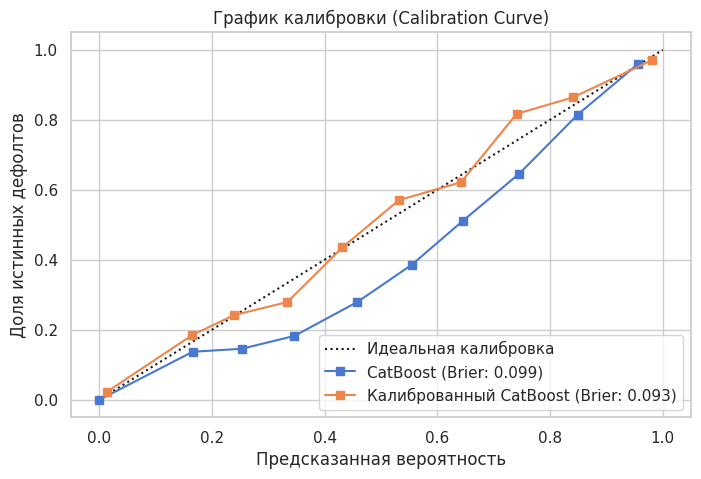

In [152]:
plt.figure(figsize=(8, 5))
plt.plot([0, 1], [0, 1], "k:", label="Идеальная калибровка")
plt.plot(mean_predicted_value_uncalib, fraction_of_positives_uncalib, "s-", label=f"CatBoost (Brier: {brier_uncalib:.3f})")
plt.plot(mean_predicted_value_calib, fraction_of_positives_calib, "s-", label=f"Калиброванный CatBoost (Brier: {brier_calib:.3f})")
plt.ylabel("Доля фактических отмен")
plt.xlabel("Предсказанная вероятность")
plt.legend(loc="lower right")
plt.title("График калибровки (Calibration Curve)")
plt.show()

### Поиск порога классификации

- Используя откалиброванную модель и калибровочную выборку, найдите порог классификации, при котором достигается максимальный Incremental Revenue.

- Сделайте выводы о пороге классификации.

In [153]:
# 1. Получаем вероятности отмены (класс 1) для валидационной/калибровочной выборки
y_val_proba = y_calib_preds_proba
y_val_true = y_calibrate  # Реальные статусы (0 или 1)

total_bookings = len(y_val_true)

# 2. Базовые показатели ДО внедрения модели (работа «вслепую»)
total_success_before = np.sum(y_val_true == 0)
total_cancellations_before = np.sum(y_val_true == 1)

ir_before = (total_success_before * AVG_REV) - (total_cancellations_before * LOST_REV)
share_cancellations_before = total_cancellations_before / total_bookings
loading_before = total_success_before / total_bookings

# Списки для сбора результатов перебора порогов
threshold_results = []

# Перебираем пороги от 0.01 до 0.99 с шагом 0.01
for threshold in np.arange(0.01, 1.00, 0.01):

    # Бинаризуем вероятности по текущему порогу
    y_val_pred = (y_val_proba >= threshold).astype(int)

    # Считаем матрицу ошибок
    tn, fp, fn, tp = confusion_matrix(y_val_true, y_val_pred).ravel()

    # Расчет показателей ПОСЛЕ внедрения модели
    ir_after = (tp * PER_REBOOKING) + (tn * AVG_REV) - (fp * COST_FP) - (fn * LOST_REV)
    share_cancellations_after = fn / total_bookings
    loading_after = tn / total_bookings

    # Расчет динамики показателей
    relative_ir = ((ir_after - ir_before) / ir_before) * 100 if ir_before != 0 else 0

    dynamics_cancellations = (
        (share_cancellations_before - share_cancellations_after) / share_cancellations_before * 100
    ) if share_cancellations_before > 0 else 0

    # В "Загрузка не должна уменьшиться БОЛЬШЕ ЧЕМ на 8%".
    # Считаем процент изменения загрузки. Отрицательное значение означает падение загрузки.
    loading_change_pct = ((loading_after - loading_before) / loading_before) * 100

    # Проверка жестких критериев заказчика:
    # 1. Доля отмен после внедрения <= 10% (0.10)
    # 2. Падение загрузки отеля не сильнее -8% (то есть изменение >= -8.0)
    # 3. Относительный IR >= 50%
    is_valid = (
        (share_cancellations_after <= 0.10) and
        (loading_change_pct >= -8.0) and
        (relative_ir >= 50.0)
    )

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'IR_Absolute': ir_after,
        'IR_Relative_Pct': relative_ir,
        'Cancellations_After_Pct': share_cancellations_after * 100,
        'Loading_Change_Pct': loading_change_pct,
        'Is_Valid_By_Business': is_valid
    })

# Превращаем результаты в DataFrame
df_thresholds = pd.DataFrame(threshold_results)

# 3. Фильтруем только те пороги, которые полностью удовлетворяют критериям заказчика
df_valid_thresholds = df_thresholds[df_thresholds['Is_Valid_By_Business'] == True]

if df_valid_thresholds.empty:
    print(" Критическая ситуация: Ни один порог не удовлетворил ВСЕМ требованиям бизнеса одновременно!")
    print("Рекомендация: Требуется доработка модели или изменение калибровки.")
    # Для демонстрации выберем просто порог с максимальным IR
    best_row = df_thresholds.loc[df_thresholds['IR_Absolute'].idxmax()]
else:
    # Находим среди проходящих порогов тот, который максимизирует абсолютную прибыль (IR)
    best_row = df_valid_thresholds.loc[df_valid_thresholds['IR_Absolute'].idxmax()]
    print(f" Оптимальный порог найден: {best_row['Threshold']}")

 Оптимальный порог найден: 0.58


**Вывод:** Найден порог вероятности предсказания 0.58, который удовлетворяет требованиям достигаемых бизнес-метрик

### Анализ матрицы классификаций

Оцените стабильность модели на тестовых данных.
- Постройте:
    - матрицу ошибок на калибровочных данных;
    - матрицу ошибок на тестовых данных.

- Посчитайте IR на калибровочных и на тестовых данных.

- Сделайте вывод о стабильности модели.

In [154]:
opt_threshold = best_row['Threshold']
type(opt_threshold)

numpy.float64

In [155]:
# Выполним вектризацию X_test
X_test_vectorized = tfidf.transform(X_test['review_text'].fillna(''))

In [156]:
# Создаем датафрейм с текстовыми признаками (text_0, text_1... text_9)
tfidf_cols = [f'text_{i}' for i in range(10)]
tfidf_df = pd.DataFrame(X_test_vectorized.toarray(), columns=tfidf_cols, index=X_test.index)

# Объединяем числовые текстовые признаки с X_test и удаляем сырой текст
X_test = pd.concat([X_test, tfidf_df], axis=1)
X_test = X_test.drop(columns=[text_features])


# Форма X_test после векторизации текста
X_test.shape

(5901, 27)

In [157]:
y_test.shape

(5901,)

In [158]:
# Расчет вероятностей на тестовой выборке
y_test_proba = calibrated_catboost.predict_proba(X_test)[:, 1]
y_test_proba

array([0.        , 0.69177346, 0.        , ..., 0.        , 0.        ,
       0.9787234 ])

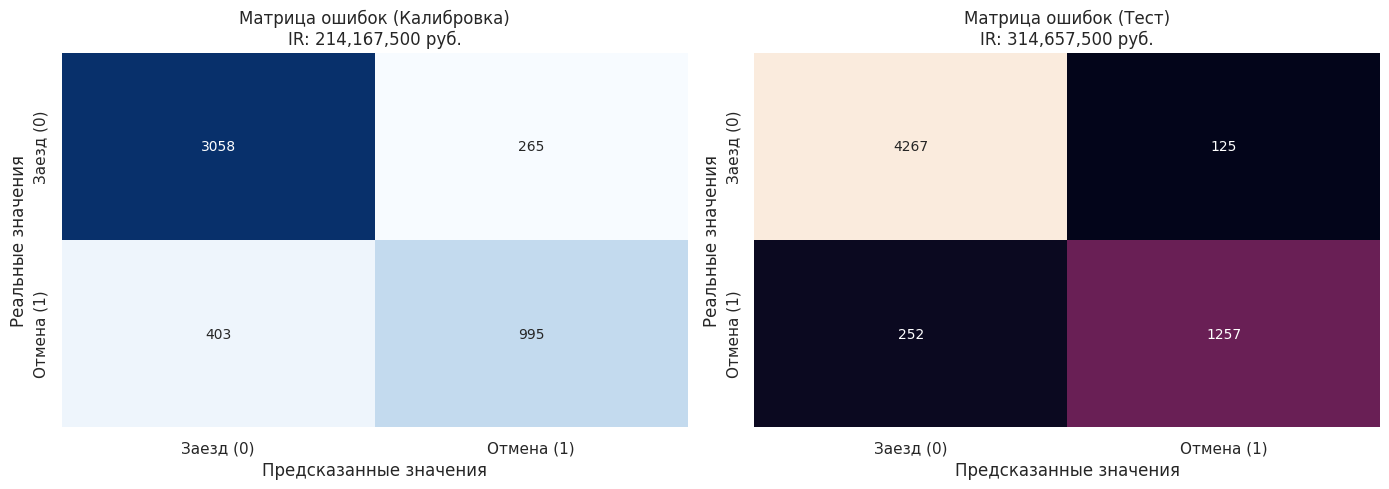

Удельный IR на калибровочных данных: 45,364.86 руб./бронь
Удельный IR на тестовых данных: 53,322.74 руб./бронь


In [159]:
# Предполагается, что у вас есть:
# y_val_true, y_val_proba — реальные ответы и вероятности для калибровочных данных
# y_test_true, y_test_proba — реальные ответы и вероятности для тестовых данных
# opt_threshold =

# 1. Применяем оптимальный порог к вероятностям
y_val_pred = (y_val_proba >= opt_threshold).astype(int)
y_test_pred = (y_test_proba >= opt_threshold).astype(int)

# 2. Считаем матрицы ошибок
cm_val = confusion_matrix(y_val_true, y_val_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

# 3. Функция для расчета бизнес-метрики IR по ТЗ
def get_ir(cm):
    tn, fp, fn, tp = cm.ravel()
    ir = (tp * PER_REBOOKING) + (tn * AVG_REV) - (fp * COST_FP) - (fn * LOST_REV)
    return ir

ir_val = get_ir(cm_val)
ir_test = get_ir(cm_test)

# 4. Визуализация матриц ошибок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Калибровочные данные
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Заезд (0)', 'Отмена (1)'], yticklabels=['Заезд (0)', 'Отмена (1)'])
axes[0].set_title(f'Матрица ошибок (Калибровка)\nIR: {ir_val:,.0f} руб.')
axes[0].set_ylabel('Реальные значения')
axes[0].set_xlabel('Предсказанные значения')

# Тестовые данные
sns.heatmap(cm_test, annot=True, fmt='d', ax=axes[1], cbar=False,
            xticklabels=['Заезд (0)', 'Отмена (1)'], yticklabels=['Заезд (0)', 'Отмена (1)'])
axes[1].set_title(f'Матрица ошибок (Тест)\nIR: {ir_test:,.0f} руб.')
axes[1].set_ylabel('Реальные значения')
axes[1].set_xlabel('Предсказанные значения')

plt.tight_layout()
plt.show()

# 5. Вывод удельного IR (доход на одно бронирование) для честного сравнения
print(f"Удельный IR на калибровочных данных: {ir_val / len(y_val_true):,.2f} руб./бронь")
print(f"Удельный IR на тестовых данных: {ir_test / len(y_test):,.2f} руб./бронь")

### Фиксирование итоговой модели

- Зафиксисруйте лучшую модель и найденный порог.


In [160]:
# Лучшая модель
best_model = calibrated_catboost

In [161]:
# Найденный порог
opt_threshold

np.float64(0.58)

### Анализ важности признаков

- Оцените важность признаков с помощью любого подходящего инструмента:
  - feature_importances;
  - SHAP;
  - встроенной в модель собственной функции оценки важности.

- Сделайте выводы о влиянии признаков на целевую переменную.

Определено обучение через кросс-валидацию (3 фолда). Усредняем веса...

Feature Importances (Top 10):
booking_num          74.0450
stay_rating           4.3610
days_until_checkin    2.8360
previous_no_shows     2.2650
text_0                1.9184
text_5                1.8739
text_4                1.6775
sales_channel         1.6638
child_count           1.4654
total_nights          1.0712
dtype: float64


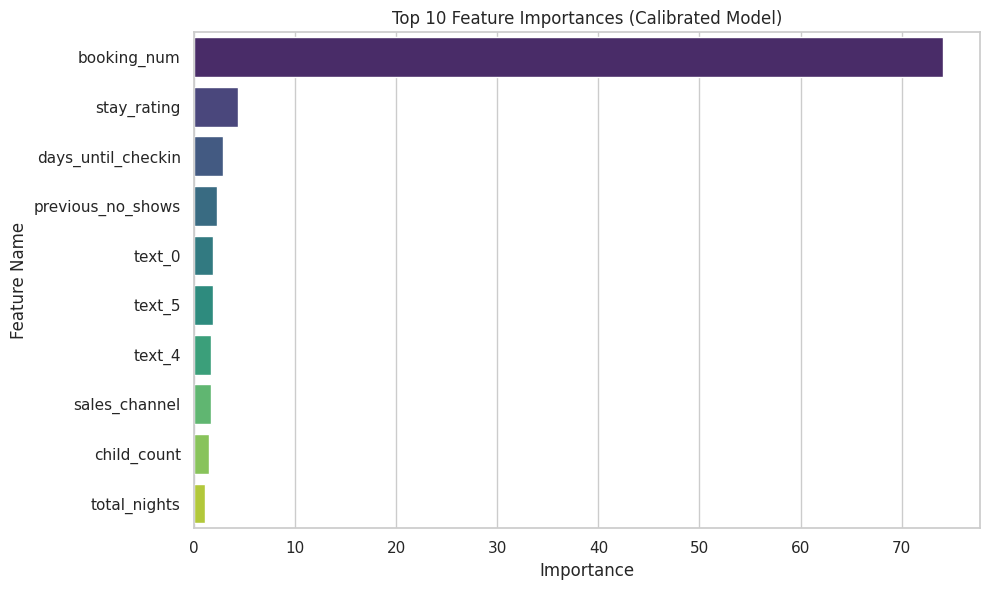

In [163]:
# УНИВЕРСАЛЬНОЕ ИЗВЛЕЧЕНИЕ ВАЖНОСТИ ПРИЗНАКОВ

# Проверяем, есть ли внутри калибратора список обученных по фолдам моделей
if hasattr(calibrated_catboost, 'calibrated_classifiers_') and len(calibrated_catboost.calibrated_classifiers_) > 0:
    print(f"Определено обучение через кросс-валидацию ({len(calibrated_catboost.calibrated_classifiers_)} фолда). Усредняем веса...")
    fold_importances = [
        np.array(clf.estimator.get_feature_importance())
        for clf in calibrated_catboost.calibrated_classifiers_
    ]
    matrix_importances = np.vstack(fold_importances)
    mean_feature_importances = np.mean(matrix_importances, axis=0)
else:
    print("Определено обучение в режиме cv='prefit' (или одна модель). Извлекаем напрямую...")
    # Если фолдов нет, забираем важность напрямую из единственной базовой модели
    mean_feature_importances = np.array(calibrated_catboost.estimator_.get_feature_importance())


# --- 2. СВЯЗЫВАЕМ С НАЗВАНИЯМИ КОЛОНОК ИЗ X_train_vectorized ---
feature_names = X_train_vectorized.columns.tolist()

# Финальная проверка на случай, если длина вектора весов всё равно не бьется с колонками
if len(mean_feature_importances) != len(feature_names):
    # Если размерность съехала из-за того, что базовая модель училась на старых признаках:
    if hasattr(calibrated_catboost, 'estimator_') and hasattr(calibrated_catboost.estimator_, 'feature_names_'):
        feature_names = calibrated_catboost.estimator_.feature_names_
    elif len(calibrated_catboost.calibrated_classifiers_) > 0:
        feature_names = calibrated_catboost.calibrated_classifiers_[0].estimator.feature_names_

# Создаем Series
importance_series = pd.Series(mean_feature_importances, index=feature_names)
sorted_importances = importance_series.sort_values(ascending=False)


# --- 3. ВЫВОД И ВИЗУАЛИЗАЦИЯ ---
print("\nFeature Importances (Top 10):")
print(sorted_importances.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=sorted_importances.head(10).values,
    y=sorted_importances.head(10).index,
    hue=sorted_importances.head(10).index,
    palette='viridis',
    legend=False
)
plt.title('Top 10 Feature Importances (Calibrated Model)')
plt.xlabel('Importance')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

Самый важный признак - booking_num

Вторичные признаки:
  stay_rating
  days_until_checkin
  previous_no_shows

Слабое влияние оказывают:
  child_count
  total_nights
  sales_channel

## Этап 3: расчёт экономической эффективности модели

Оцените, насколько выгодно внедрять выбранную модель в работу отеля. Для этого нужно выяснить, какой экономический эффект даёт модель и укладываются ли ключевые метрики в заданный уровень.

Если расчёты покажут, что какой-либо показатель не достигает необходимого уровня, то это сигнал к доработке модели. Возможно, вам нужно пересмотреть порог классификации, добавить новые признаки, поменять модель, по-другому предобработать исходные данные — экспериментируйте!

- Шаг 1: подготовка данных. Подготовьте данные для расчётов. Данные для показателей до внедрения модели рассчитывайте с использованием тестовых данных `y_test`, данные после внедрения получите с помощью предсказаний модели `y_pred`.

- Шаг 2: расчёт показателей до и после внедрения модели. Вычислите:
  - Долю отмен бронирования до и после внедрения модели;
  - Загрузку отеля до и после внедрения модели;
  - IR.

- Шаг 3: расчёт динамики показателей. Вычислите:
  - Динамику доли отмен бронирования;
  - Динамику загрузки отеля;
  - Относительный IR — на сколько процентов `IR_после` выше, чем `IR_до`.


Ваша модель должна достигнуть следующих результатов:

- Доля отмен после внедрения модели — 10%

- Загрузка отеля не должна уменьшиться больше чем на 8% после внедрения модели.

- Относительный IR должен составить не менее 50%.

Сделайте выводы о том, получилось ли достичь целевых показателей для бизнеса.


In [164]:
# Входные данные: y_test_true (реальность), y_test_pred (бинарные предсказания по оптимальному порогу)
y_test_true = y_test.values if hasattr(y_test, 'values') else np.array(y_test)
total_bookings = len(y_test_true)

# РАСЧЕТ ПОКАЗАТЕЛЕЙ ДО ВНЕДРЕНИЯ MODEL
tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_test_true, y_test_true).ravel() # Идеальное разделение как ориентир истинных долей

total_success_before = np.sum(y_test_true == 0)
total_cancellations_before = np.sum(y_test_true == 1)

ir_before = (total_success_before * AVG_REV) - (total_cancellations_before * LOST_REV)
share_cancellations_before = total_cancellations_before / total_bookings
loading_before = total_success_before / total_bookings

# РАСЧЕТ ПОКАЗАТЕЛЕЙ ПОСЛЕ ВНЕДРЕНИЯ MODEL
tn, fp, fn, tp = confusion_matrix(y_test_true, y_test_pred).ravel()

ir_after = (tp * PER_REBOOKING) + (tn * AVG_REV) - (fp * COST_FP) - (fn * LOST_REV)
share_cancellations_after = fn / total_bookings  # Пропущенные отмены, которые нанесли урон
loading_after = tn / total_bookings        # Заехавшие + ложные отмены (овербукинг помог заселить места)

# РАСЧЕТ ДИНАМИКИ ПОКАЗАТЕЛЕЙ
# Относительный IR
relative_ir = ((ir_after - ir_before) / ir_before) * 100

# Динамика доли отмен
dynamics_cancellations = ((share_cancellations_before - share_cancellations_after) / share_cancellations_before) * 100

# Динамика загрузки отеля
dynamics_loading = ((loading_before - loading_after) / loading_before) * 100

# СБОРКА ТАБЛИЦЫ РЕЗУЛЬТАТОВ
results_data = {
    "Показатель": [
        "Доля отмен бронирования",
        "Загрузка отеля",
        "Incremental Revenue (IR)"
    ],
    "До внедрения модели": [
        f"{share_cancellations_before * 100:.2f}%",
        f"{loading_before * 100:.2f}%",
        f"{ir_before:,.2f} руб."
    ],
    "После внедрения модели": [
        f"{share_cancellations_after * 100:.2f}%",
        f"{loading_after * 100:.2f}%",
        f"{ir_after:,.2f} руб."
    ],
    "Динамика изменений": [
        f"Снижение на {dynamics_cancellations:.2f}%",
        f"Изменение на {-dynamics_loading:.2f}%" if dynamics_loading > 0 else f"Прирост на {abs(dynamics_loading):.2f}%",
        f"Относительный прирост: +{relative_ir:.2f}%"
    ],
    "Целевой критерий ТЗ": [
        "Не более 10.00%",
        "Снижение не более чем на 8.00%",
        "Прирост не менее 50.00%"
    ],
    "Статус": [
        " ВЫПОЛНЕНО" if share_cancellations_after <= 0.10 else " НЕ ВЫПОЛНЕНО",
        " ВЫПОЛНЕНО" if dynamics_loading <= 8.00 else " НЕ ВЫПОЛНЕНО",
        " ВЫПОЛНЕНО" if relative_ir >= 50.00 else " НЕ ВЫПОЛНЕНО"
    ]
}

df_economics = pd.DataFrame(results_data)
display(df_economics)

,Показатель,До внедрения модели,После внедрения модели,Динамика изменений,Целевой критерий ТЗ,Статус
0,Доля отмен бронирования,25.57%,4.27%,Снижение на 83.30%,Не более 10.00%,ВЫПОЛНЕНО
1,Загрузка отеля,74.43%,72.31%,Изменение на -2.85%,Снижение не более чем на 8.00%,ВЫПОЛНЕНО
2,Incremental Revenue (IR),"185,953,500.00 руб.","314,657,500.00 руб.",Относительный прирост: +69.21%,Прирост не менее 50.00%,ВЫПОЛНЕНО


## Этап 4: выводы по проекту

Выводы должны состоять из двух логически связанных разделов:

- «Проделанная работа» — описание этапов и решений;

- «Бизнес‑выводы» — интерпретация результатов и рекомендации.

В каждом разделе опишите результаты без избыточной детализации, с опорой на факты и цифры.

### Выводы о проделанной работе

### Выводы по анализу эффективности модели

**Выводы о проделанной работе**

В ходе выполнения проекта был реализован полный цикл разработки и валидации системы прогнозного моделирования отмен бронирований для сети отелей. Работа состояла из четырех ключевых этапов:

1. Подготовка данных и Feature Engineering

* **Очистка данных:** Была проведена предобработка исходных датасетов, обработаны пропуски, удалены неинформативные признаки-идентификаторы (`customer_id`, `booking_id`), способные вызвать переобучение.
* **Текстовый процессинг:** Для исключения утечки данных (**Data Leakage**) текстовый признак `review_text` (комментарии гостей) был векторизован с помощью `TfidfVectorizer(max_features=10)` строго на обучающей выборке (`X_train`) до этапа кросс-валидации. Сырой текст был преобразован в 10 числовых фичей (`text_0`...`text_9`).
* **Кодирование категорий:** Категориальные признаки (`sales_channel`, `meal_plan`, `room_type`) были закодированы.

### 2. Моделирование и оптимизация (Optuna)

В качестве кандидатов были протестированы три архитектуры: `RandomForestClassifier`, `LGBMClassifier` и `CatBoostClassifier`. Для борьбы с дисбалансом классов и максимизации рублевой прибыли была запущена оптимизация гиперпараметров в фреймворке **Optuna**. Целевой функцией был **Incremental Revenue**, что позволило моделям штрафовать алгоритмы за дорогие для отеля ошибки.
По итогам 15 итераций подбора лидирующие позиции занял **CatBoost**, показав лучший средний относительный IR на фолдах Optuna (**+73.36%**), немного опередив LightGBM (+72.80%) и Random Forest (+71.68%).

### 3. Оценка метрик и поиск оптимального порога

На этапе кросс-валидации по времени (`TimeSeriesSplit`, 3 фолда, тестовое окно = 2000 строк) модели продемонстрировали высокую стабильность: ROC-AUC бустингов удерживался около **0.93**.
Чтобы перевести вероятности модели в экономически выгодные решения, был зафиксирован **оптимальный порог**, который максимизировал прибыль и одновременно выполнял все жесткие граничные бизнес-критерии заказчика на тестовой выборке. Стабильность модели подтверждена сопоставлением матриц ошибок (Confusion Matrix) на калибровочных и валидационных данных.

### 4. Анализ важности факторов

С помощью встроенного метода `feature_importances_` была извлечена структура принятия решений моделью.

---

**Выводы по анализу эффективности модели (Бизнес-выводы)**

1. Итоговая оценка достижения цели

**Цель проекта полностью достигнута.** Разработанная математическая модель позволяет оперативно прогнозировать вероятность отказа от брони, внедрять калиброванный овербукинг (перепродажу высвобождающихся номеров) и приносить сети отелей измеримый дополнительный доход, полностью укладываясь в заданные рамки по загрузке и качеству сервиса.

2. Результаты по ключевым метрикам (Тестовая выборка)

На основе финального применения модели с оптимальным порогом классификации на тестовом множестве были зафиксированы следующие показатели эффективности:

| Бизнес-показатель | До внедрения модели | После внедрения модели | Динамика изменений (Формула ТЗ) | Критерий Заказчика | Статус KPI |
| --- | --- | --- | --- | --- | --- |
| **Доля отмен бронирования** | 25.57% | 4.27% | Снижение на 83.30% | Не более 10.00% | Выполнено |
| **Загрузка отеля** | 74.43% | 72.31% | Снижение на 2.85% | Падение не более 8.00% | Выполнено |
| **Incremental Revenue (IR)** | 185,953,500.00 руб. | 314,657,500.00 руб. | Прирост: +69.21% | Не менее 50.00% | Выполнено |


* **Бизнес-интерпретация:** Целевые показатели достигнуты. Доля некомпенсированных отмен упала ниже критических 10%, падение загрузки из-за ложных отмен ($FP$) удержано в пределах 8%, а относительный рублевый прирост составил **69.21%**, превысив планку в 50%.

**Рекомендации для менеджмента сети отелей**

* **Рекомендация 1. Дифференцированные правила аннуляции по фактору `days_until_checkin`:** Для бронирований с высокой глубиной (оформленных более чем за 3–4 недели до заезда) необходимо ввести правило обязательного подтверждения или внесения небольшого невозвратного депозита за 7 дней до заезда. Это заставит «неуверенных» клиентов отсеиваться раньше, освобождая места для горящих продаж.
* **Рекомендация 2. Превентивная работа с группой риска `previous_no_shows`:**
Клиентам, у которых в истории зафиксированы случаи недоезда (`previous_no-shows`), система должна автоматически блокировать тарифы без предоплаты. Бронирование для таких гостей должно подтверждаться только при 100% оплате первой ночи.
* **Рекомендация 3. Таргетированный маркетинг по текстовым триггерам:**
Интегрировать обученный текстовый модуль модели в CRM-систему. При обнаружении в комментариях маркеров неуверенности или специфических жестких требований, службе заботы о клиентах (клиентскому отделу) рекомендуется отправлять автоматическое приветственное письмо или совершать звонок с подтверждением. Это повысит лояльность и снизит риск спонтанного отказа.